# Abalone Yaş Grubu Sınıflandırması — Denetimli Makine Öğrenmesi

| | |
|---|---|
| **Veri seti** | Abalone (UCI ML Repository / OpenML), 4177 gözlem |
| **Problem** | Çok sınıflı sınıflandırma: `Rings` → Yaş grubu (Young / Middle / Old) |
| **Modeller** | Lojistik Regresyon · KNN · Karar Ağacı · Budanmış Ağaç · Bagging · Random Forest · XGBoost |
| **Ayarlama** | GridSearchCV, 5 katlı Stratified CV, ölçüt: F1-macro |
| **Dengesizlik** | Yok / `class_weight` / SMOTENC — eğitim setinde CV ile karşılaştırma |
| **Açıklanabilirlik** | SHAP (TreeExplainer, XGBoost) |
| **Ek** | ipywidgets + Groq (Llama 3.1) ile etkileşimli tahmin arayüzü |

> Bu notebook projenin **düzeltilmiş** sürümüdür. İlk sürümdeki hatalar ve yapılan
> düzeltmeler `README.md` dosyasındaki *Düzeltmeler* bölümünde listelenmiştir.

## 0. Kütüphaneler ve Ayarlar

In [1]:
# Gerekirse: %pip install -r requirements.txt
import os, time, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

from sklearn.base            import clone
from sklearn.datasets        import fetch_openml
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     GridSearchCV, cross_validate)
from sklearn.preprocessing   import StandardScaler, label_binarize
from sklearn.pipeline        import Pipeline
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics         import (accuracy_score, balanced_accuracy_score,
                                     f1_score, precision_score, recall_score,
                                     roc_auc_score, roc_curve, auc,
                                     classification_report, confusion_matrix)
from sklearn.linear_model    import LogisticRegression
from sklearn.neighbors       import KNeighborsClassifier
from sklearn.tree            import DecisionTreeClassifier
from sklearn.ensemble        import BaggingClassifier, RandomForestClassifier
from xgboost                 import XGBClassifier
from imblearn.over_sampling  import SMOTENC
from imblearn.pipeline       import Pipeline as ImbPipeline
import shap
import sklearn

# sample_weight yalnizca XGBoost'un fit() metoduna gitsin, skorlayiciya gitmesin
# (aksi halde GridSearchCV agirlikli F1 hesaplar ve modeller karsilastirilamaz).
sklearn.set_config(enable_metadata_routing=True)

RANDOM_STATE = 42
FIG_DIR      = 'figures'
os.makedirs(FIG_DIR, exist_ok=True)

print("Kutuphaneler yuklendi.")

Kutuphaneler yuklendi.


In [2]:
plt.rcParams.update({
    'figure.facecolor' : '#0D1117', 'axes.facecolor'  : '#161B22',
    'axes.edgecolor'   : '#30363D', 'axes.labelcolor' : '#C9D1D9',
    'axes.titlecolor'  : '#F0F6FC', 'xtick.color'     : '#8B949E',
    'ytick.color'      : '#8B949E', 'grid.color'      : '#21262D',
    'grid.linewidth'   : 0.6,       'text.color'      : '#C9D1D9',
    'font.family'      : 'DejaVu Sans', 'font.size'   : 11,
    'axes.titlesize'   : 13,        'axes.titleweight': 'bold',
    'axes.labelsize'   : 11,        'figure.dpi'      : 130,
    'legend.facecolor' : '#161B22', 'legend.edgecolor': '#30363D',
})

C = ['#58A6FF','#3FB950','#FF7B72','#D2A8FF','#FFA657','#79C0FF','#56D364']

## 1. Veri Setinin Tanıtımı

Abalone bir deniz salyangozudur. Yaşı, kabuk kesilip halkalar mikroskopla sayılarak
bulunur (`yaş ≈ Rings + 1.5`). Amaç bu zahmetli işlem yerine **fiziksel ölçümlerle**
yaş grubunu tahmin etmektir.

| Değişken | Tür | Açıklama |
|---|---|---|
| `Sex` | Kategorik | M (erkek) / F (dişi) / I (yavru) |
| `Length`, `Diameter`, `Height` | Sürekli | Kabuk boyutları |
| `WholeWeight`, `ShuckedWeight`, `VisceraWeight`, `ShellWeight` | Sürekli | Toplam / et / iç organ / kuru kabuk ağırlığı |
| `Rings` | Tamsayı | Halka sayısı → hedef değişken buradan türetilir |

> **Birim notu:** UCI sürümünde tüm sürekli değişkenler **200'e bölünmüştür**
> (orijinal birimler mm ve gram). Bu yüzden ör. `Length = 0.455` aslında 91 mm'dir.

In [3]:
abalone = fetch_openml(name='abalone', version=1, as_frame=True, parser='auto')
df = abalone.frame

df.columns = ['Sex','Length','Diameter','Height',
              'WholeWeight','ShuckedWeight','VisceraWeight','ShellWeight','Rings']
df['Rings'] = df['Rings'].astype(int)

print(f"Veri seti boyutu: {df.shape}")
df.head()

Veri seti boyutu: (4177, 9)


,Sex,Length,Diameter,Height,WholeWeight,ShuckedWeight,VisceraWeight,ShellWeight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [4]:
num_cols = ['Length','Diameter','Height','WholeWeight',
            'ShuckedWeight','VisceraWeight','ShellWeight','Rings']

desc = df[num_cols].describe().T
desc['skewness'] = df[num_cols].skew()
desc['kurtosis'] = df[num_cols].kurt()
desc['median']   = df[num_cols].median()
desc['IQR']      = df[num_cols].quantile(0.75) - df[num_cols].quantile(0.25)
desc = desc[['count','mean','median','std','IQR','min','25%','75%','max','skewness','kurtosis']]

desc.style.background_gradient(subset=['mean','std','skewness'], cmap='Blues').format(precision=4)

,count,mean,median,std,IQR,min,25%,75%,max,skewness,kurtosis
Length,4177.0000,0.5240,0.5450,0.1201,0.1650,0.0750,0.4500,0.6150,0.8150,-0.6399,0.0646
Diameter,4177.0000,0.4079,0.4250,0.0992,0.1300,0.0550,0.3500,0.4800,0.6500,-0.6092,-0.0455
Height,4177.0000,0.1395,0.1400,0.0418,0.0500,0.0000,0.1150,0.1650,1.1300,3.1288,76.0255
WholeWeight,4177.0000,0.8287,0.7995,0.4904,0.7115,0.0020,0.4415,1.1530,2.8255,0.5310,-0.0236
ShuckedWeight,4177.0000,0.3594,0.3360,0.2220,0.3160,0.0010,0.1860,0.5020,1.4880,0.7191,0.5951
VisceraWeight,4177.0000,0.1806,0.1710,0.1096,0.1595,0.0005,0.0935,0.2530,0.7600,0.5919,0.0840
ShellWeight,4177.0000,0.2388,0.2340,0.1392,0.1990,0.0015,0.1300,0.3290,1.0050,0.6209,0.5319
Rings,4177.0000,9.9337,9.0000,3.2242,3.0000,1.0000,8.0000,11.0000,29.0000,1.1141,2.3307


In [5]:
print("Kategorik Degisken — Sex:")
print(pd.concat([df['Sex'].value_counts(),
                 (df['Sex'].value_counts(normalize=True) * 100).round(1)],
                axis=1, keys=['n', '%']))

Kategorik Degisken — Sex:
        n     %
Sex            
M    1528  36.6
I    1342  32.1
F    1307  31.3


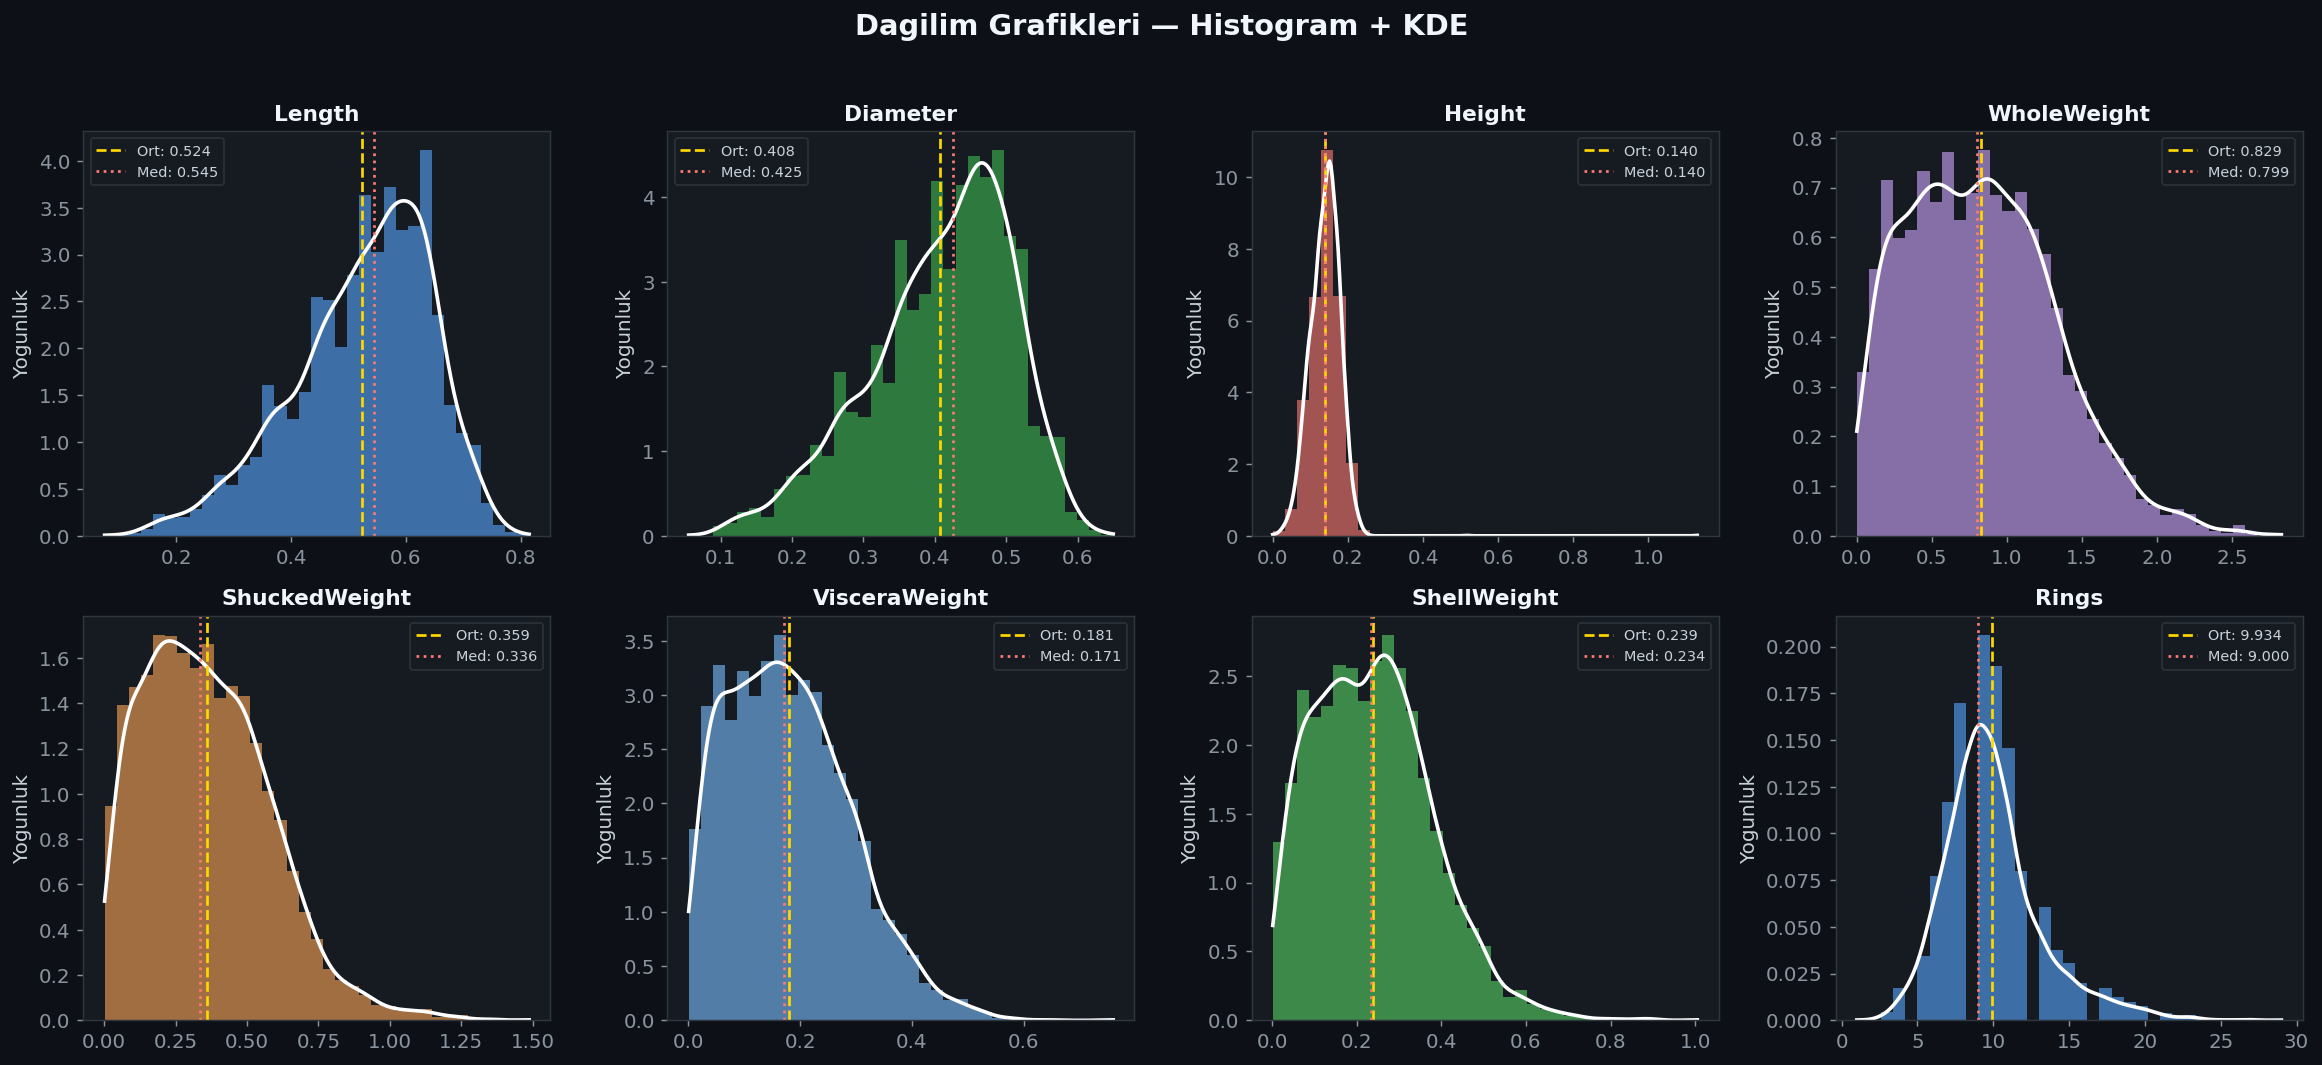

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
fig.suptitle('Dagilim Grafikleri — Histogram + KDE', fontsize=16,
             color='#F0F6FC', fontweight='bold', y=1.02)

for i, col in enumerate(num_cols):
    ax   = axes[i // 4][i % 4]
    data = df[col].dropna()
    ax.hist(data, bins=35, facecolor=C[i % len(C)], alpha=0.6,
            edgecolor='none', density=True)
    kde_x = np.linspace(data.min(), data.max(), 300)
    ax.plot(kde_x, stats.gaussian_kde(data)(kde_x), color='white', lw=2)
    ax.axvline(data.mean(),   color='#FFD700', lw=1.5, ls='--', label=f'Ort: {data.mean():.3f}')
    ax.axvline(data.median(), color='#FF7B72', lw=1.5, ls=':',  label=f'Med: {data.median():.3f}')
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_ylabel('Yogunluk')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/dagilim_grafikleri.png', dpi=130, bbox_inches='tight', facecolor='#0D1117')
plt.show()

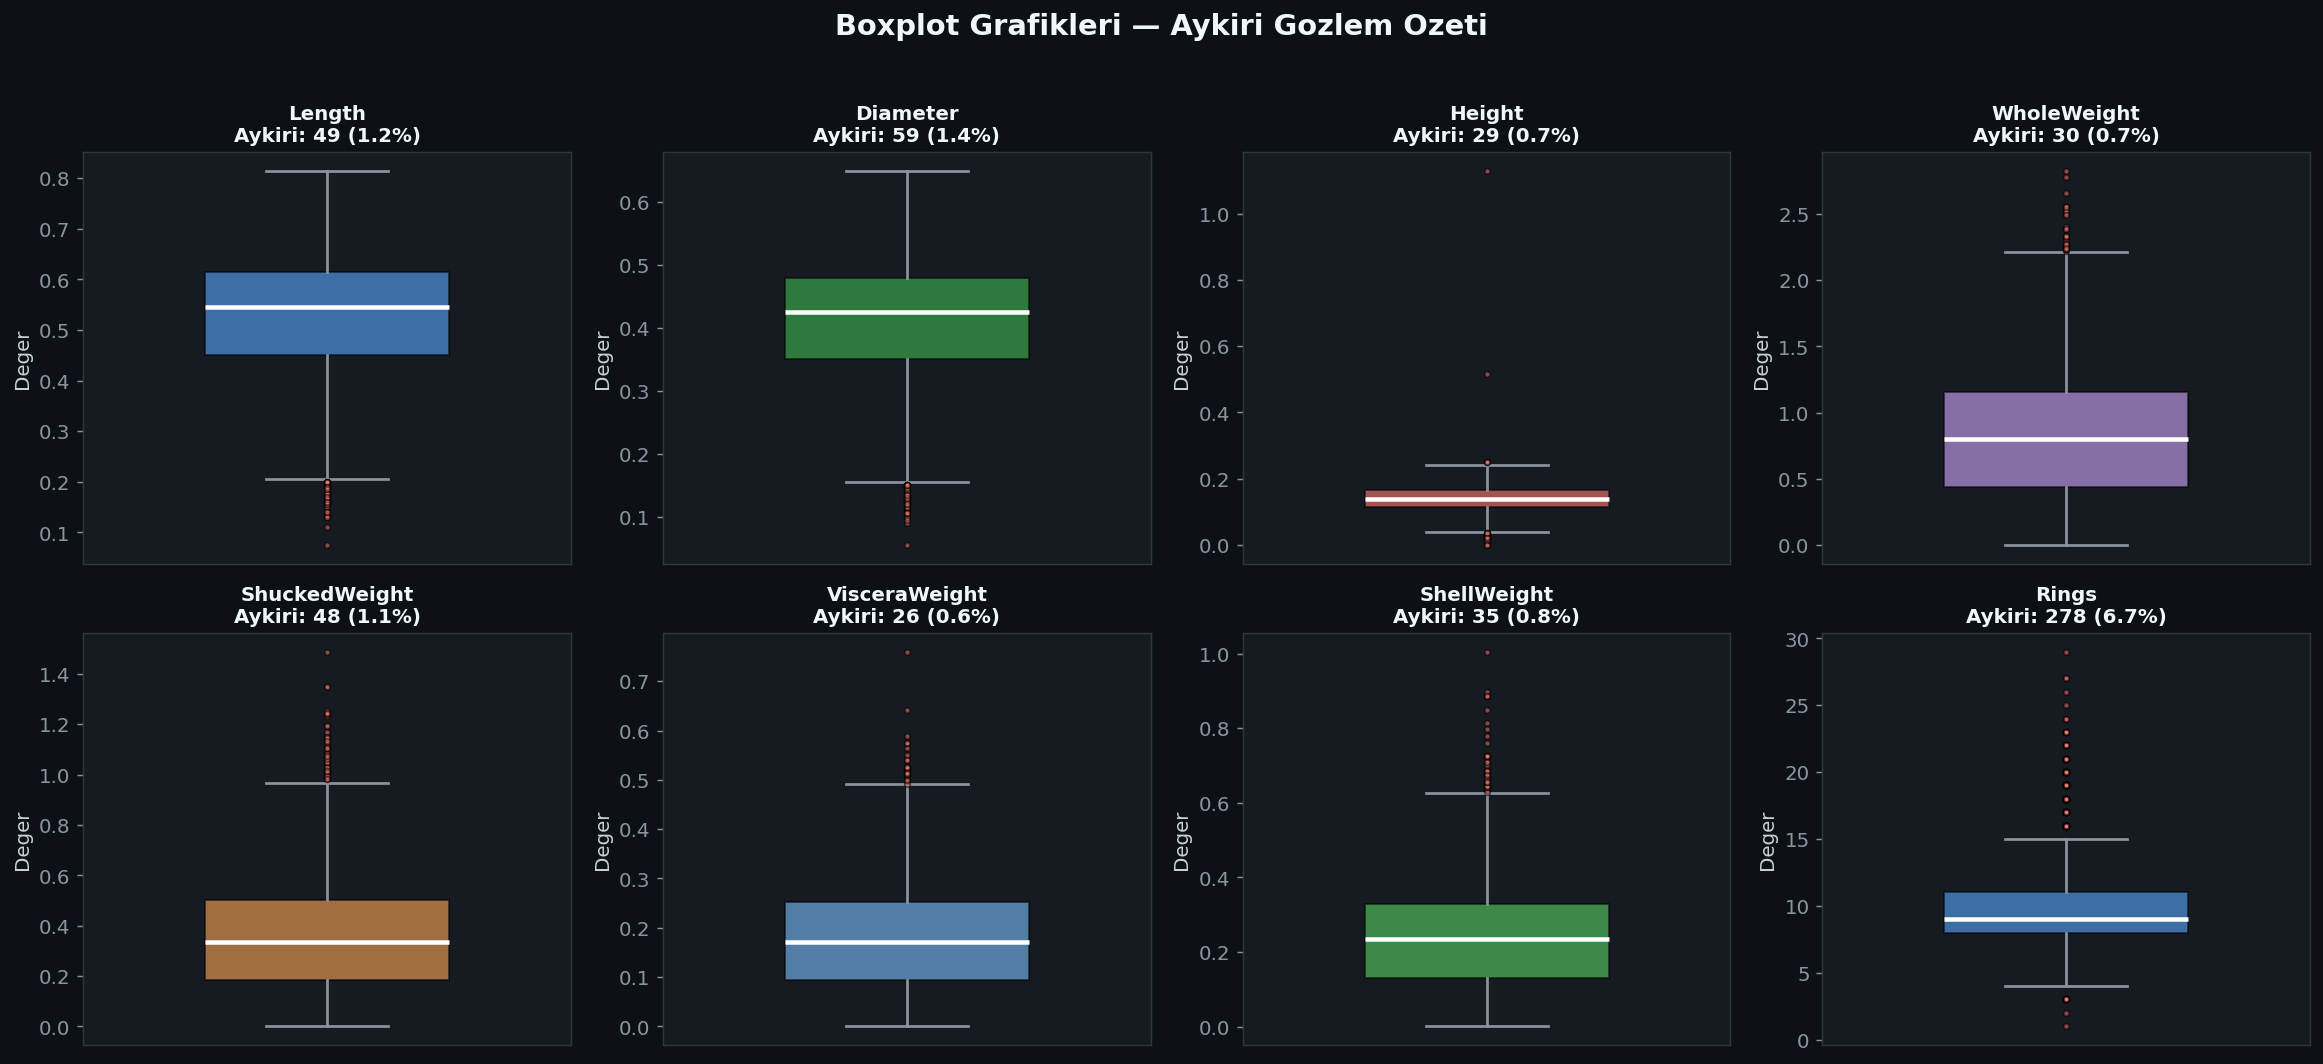

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
fig.suptitle('Boxplot Grafikleri — Aykiri Gozlem Ozeti', fontsize=16,
             color='#F0F6FC', fontweight='bold', y=1.02)

for i, col in enumerate(num_cols):
    ax   = axes[i // 4][i % 4]
    data = df[col].dropna()
    q1, q3 = data.quantile(.25), data.quantile(.75)
    iqr    = q3 - q1
    n_out  = ((data < q1-1.5*iqr) | (data > q3+1.5*iqr)).sum()
    ax.boxplot(data, vert=True, patch_artist=True, widths=0.5,
               boxprops=dict(facecolor=C[i % len(C)], alpha=0.6),
               medianprops=dict(color='white', lw=2.5),
               whiskerprops=dict(color='#8B949E', lw=1.5),
               capprops=dict(color='#8B949E', lw=1.5),
               flierprops=dict(marker='o', markerfacecolor='#FF7B72',
                               markersize=3, alpha=0.5, linestyle='none'))
    ax.set_title(f'{col}\nAykiri: {n_out} ({100*n_out/len(data):.1f}%)', fontsize=11, fontweight='bold')
    ax.set_xticks([])
    ax.set_ylabel('Deger')

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/boxplot_grafikleri.png', dpi=130, bbox_inches='tight', facecolor='#0D1117')
plt.show()

## 2. Hedef Değişken: Yaş Grubu

`Rings` üç sıralı (ordinal) sınıfa dönüştürülür:

- **Young**: Rings ≤ 8 · **Middle**: 9 ≤ Rings ≤ 11 · **Old**: Rings ≥ 12

`Rings` hedefin kaynağı olduğu için modele **özellik olarak verilmez** (aksi hâlde sızıntı olur).

In [8]:
bins   = [0, 8, 11, 100]
labels = ['Young (<=8)', 'Middle (9-11)', 'Old (>=12)']
df['Age_Group'] = pd.cut(df['Rings'], bins=bins, labels=labels)

print(pd.concat([df['Age_Group'].value_counts().sort_index(),
                 (df['Age_Group'].value_counts(normalize=True).sort_index() * 100).round(2)],
                axis=1, keys=['n', '%']))

                  n      %
Age_Group                 
Young (<=8)    1407  33.68
Middle (9-11)  1810  43.33
Old (>=12)      960  22.98


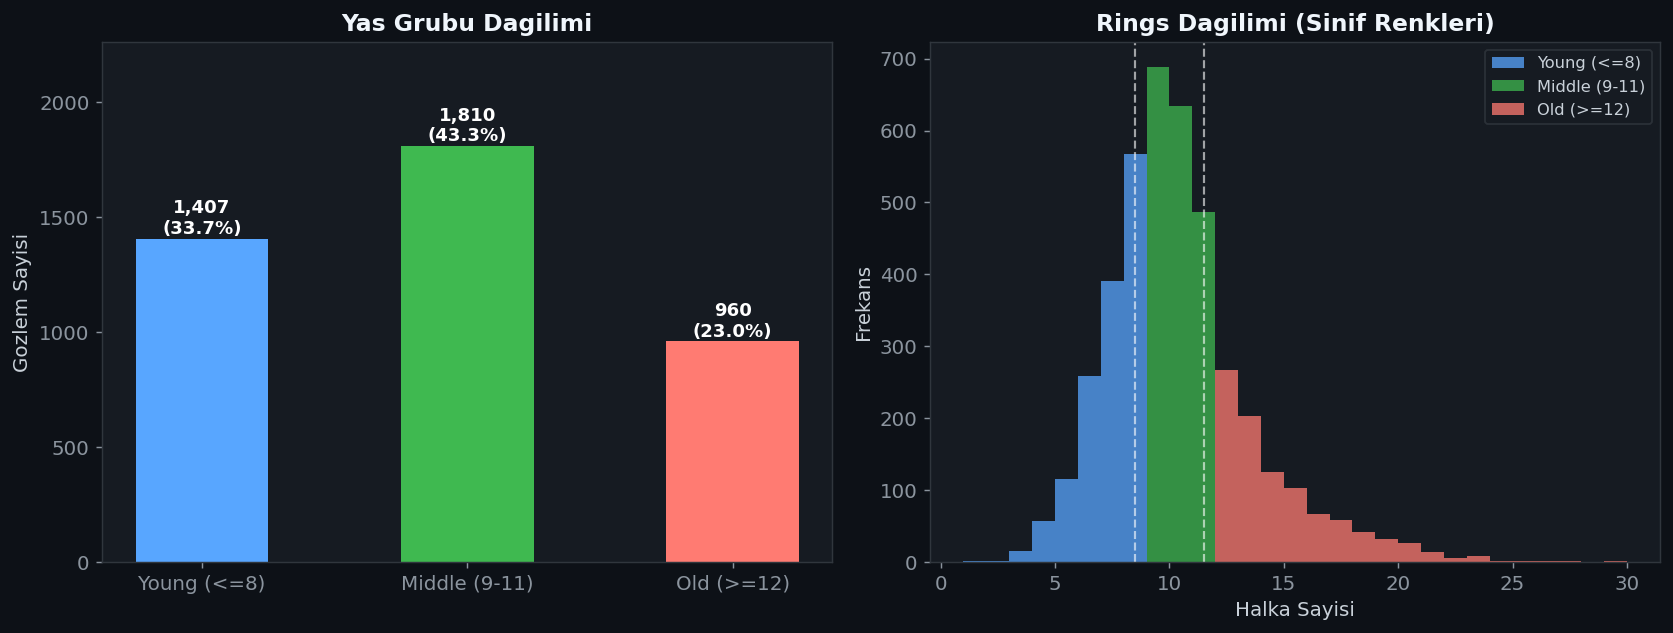

In [9]:
vc = df['Age_Group'].value_counts().sort_index()
renk_map = dict(zip(labels, [C[0], C[1], C[2]]))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

bars = axes[0].bar(vc.index, vc.values, color=list(renk_map.values()), edgecolor='none', width=0.5)
for bar, v in zip(bars, vc.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, v + 20, f'{v:,}\n({100*v/len(df):.1f}%)',
                 ha='center', fontsize=10, color='white', fontweight='bold')
axes[0].set_title('Yas Grubu Dagilimi')
axes[0].set_ylabel('Gozlem Sayisi')
axes[0].set_ylim(0, vc.max() * 1.25)

for grp, renk in renk_map.items():
    axes[1].hist(df.loc[df['Age_Group'] == grp, 'Rings'], bins=range(1, 31),
                 alpha=0.75, color=renk, label=grp, edgecolor='none')
for x in (8.5, 11.5):
    axes[1].axvline(x, color='white', lw=1.2, ls='--', alpha=0.6)
axes[1].set_title('Rings Dagilimi (Sinif Renkleri)')
axes[1].set_xlabel('Halka Sayisi')
axes[1].set_ylabel('Frekans')
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/sinif_dagilimi.png', dpi=130, bbox_inches='tight', facecolor='#0D1117')
plt.show()

Sınıflar orta derecede dengesizdir (en büyük / en küçük ≈ 1.9). Bu nedenle ana ölçüt olarak
**F1-macro** (her sınıfa eşit ağırlık) kullanılır; dengesizlik stratejileri Bölüm 5'te karşılaştırılır.

## 3. Veri Kalitesi

### 3.1 Eksik değerler

In [10]:
print("Eksik Deger Kontrolu:")
print(df.isnull().sum())
print(f"\nToplam eksik: {df.isnull().sum().sum()}")

Eksik Deger Kontrolu:
Sex              0
Length           0
Diameter         0
Height           0
WholeWeight      0
ShuckedWeight    0
VisceraWeight    0
ShellWeight      0
Rings            0
Age_Group        0
dtype: int64

Toplam eksik: 0


### 3.2 Aykırı gözlemler (IQR yöntemi)

In [11]:
kayit = []
for col in num_cols:
    s       = df[col]
    q1, q3  = s.quantile(.25), s.quantile(.75)
    iqr     = q3 - q1
    lo, hi  = q1 - 1.5*iqr, q3 + 1.5*iqr
    out     = s[(s < lo) | (s > hi)]
    kayit.append({'Degisken': col, 'Alt Sinir': round(lo, 4), 'Ust Sinir': round(hi, 4),
                  'Aykiri N': len(out), 'Aykiri %': round(100*len(out)/len(s), 2),
                  'Min aykiri': out.min() if len(out) else np.nan,
                  'Max aykiri': out.max() if len(out) else np.nan})

aykiri_df = pd.DataFrame(kayit)
print(aykiri_df.to_string(index=False))

     Degisken  Alt Sinir  Ust Sinir  Aykiri N  Aykiri %  Min aykiri  Max aykiri
       Length     0.2025     0.8625        49      1.17      0.0750      0.2000
     Diameter     0.1550     0.6750        59      1.41      0.0550      0.1500
       Height     0.0400     0.2400        29      0.69      0.0000      1.1300
  WholeWeight    -0.6258     2.2202        30      0.72      2.2205      2.8255
ShuckedWeight    -0.2880     0.9760        48      1.15      0.9815      1.4880
VisceraWeight    -0.1458     0.4922        26      0.62      0.4925      0.7600
  ShellWeight    -0.1685     0.6275        35      0.84      0.6300      1.0050
        Rings     3.5000    15.5000       278      6.66      1.0000     29.0000


In [12]:
# Aykirilar hangi yas grubuna dusuyor?
ozet = {}
for col in num_cols[:-1]:
    s      = df[col]
    q1, q3 = s.quantile(.25), s.quantile(.75)
    iqr    = q3 - q1
    mask   = (s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)
    ozet[col] = df.loc[mask, 'Age_Group'].value_counts().reindex(labels)
pd.DataFrame(ozet).T

Age_Group,Young (<=8),Middle (9-11),Old (>=12)
Length,49,0,0
Diameter,59,0,0
Height,24,2,3
WholeWeight,0,10,20
ShuckedWeight,0,26,22
VisceraWeight,0,13,13
ShellWeight,0,5,30


In [13]:
# Height icin fiziksel tutarlilik: Height / Length orani
df['_HL'] = df['Height'] / df['Length']
print("Height / Length orani (tum veri):")
print(df['_HL'].describe().round(3))

print(f"\nHeight == 0 : {(df['Height'] == 0).sum()} gozlem")
print(f"Height > 0.4: {(df['Height'] > 0.4).sum()} gozlem\n")

supheli = df[(df['Height'] == 0) | (df['Height'] > 0.4)]
print(supheli[['Sex','Length','Diameter','Height','WholeWeight','Rings','_HL']])
df = df.drop(columns='_HL')

Height / Length orani (tum veri):
count    4177.000
mean        0.265
std         0.049
min         0.000
25%         0.243
50%         0.262
75%         0.283
max         2.484
Name: _HL, dtype: float64

Height == 0 : 2 gozlem
Height > 0.4: 2 gozlem

     Sex  Length  Diameter  Height  WholeWeight  Rings       _HL
1257   I   0.430     0.340   0.000        0.428      8  0.000000
1417   M   0.705     0.565   0.515        2.210     10  0.730496
2051   F   0.455     0.355   1.130        0.594      8  2.483516
3996   I   0.315     0.230   0.000        0.134      6  0.000000


In [14]:
df_clean = df[(df['Height'] > 0) & (df['Height'] < 0.5)].copy()
print(f"Cikarilan: {len(df) - len(df_clean)} satir")
print(f"Kalan    : {len(df_clean)} gozlem")

Cikarilan: 4 satir
Kalan    : 4173 gozlem


**Çıkarılan gözlemler (4 satır)**

- **Height = 0 (2 satır):** Bir abalone'nin yüksekliği fiziksel olarak sıfır olamaz; ölçüm/veri girişi hatasıdır.
- **Height = 1.130 (1 satır):** Length = 0.455, WholeWeight = 0.594 olan küçük bir bireyin
  yüksekliği uzunluğunun ~2.5 katı olamaz (Height/Length oranı veride tipik olarak ~0.27).
- **Height = 0.515 (1 satır):** Length = 0.705 için Height/Length ≈ 0.73; tipik oranın yaklaşık 2.7 katıdır.
  Ağırlıkları normal olduğundan yüksekliğin hatalı girildiği değerlendirilmiştir.

> *İlk sürümde bu bölümde "3 satır" yazıyordu; kod ise `Height < 0.5` koşuluyla 0.515 değerini de
> çıkardığı için gerçekte 4 satır çıkarılmıştı. Metin koda uygun hâle getirildi.*

**Dokunulmayan aykırılar**

- **Length / Diameter (alt aykırılar):** Küçük değerlerde yoğunlaşır; genç (Young) bireylerin gerçek ölçümleridir.
- **Ağırlık değişkenleri (üst aykırılar):** Hiçbiri Young sınıfında değildir; büyük ve yaşlı bireylerin
  gerçek ölçümleridir, biyolojik olarak mümkündür.
- **Rings:** Hedefin kaynağıdır; sınıflara dönüştürüldüğünden ayrıca işlem gerekmez.

Temizlik yalnızca **alan bilgisine dayalı kurallarla** (etiketlere bakılmadan) yapıldığı için
eğitim/test ayrımından önce uygulanması bir sızıntı oluşturmaz.

In [15]:
print(f"{'Degisken':<16} {'Carpiklik':>10} {'Yorum':>16}")
print("-" * 46)
for col in num_cols:
    sk = stats.skew(df_clean[col])
    yorum = "Simetrik" if abs(sk) < 0.5 else ("Orta carpik" if abs(sk) < 1 else "Yuksek carpik")
    print(f"{col:<16} {sk:>10.4f} {yorum:>16}")

Degisken          Carpiklik            Yorum
----------------------------------------------
Length              -0.6413      Orta carpik
Diameter            -0.6106      Orta carpik
Height              -0.2492         Simetrik
WholeWeight          0.5281      Orta carpik
ShuckedWeight        0.7144      Orta carpik
VisceraWeight        0.5892      Orta carpik
ShellWeight          0.6209      Orta carpik
Rings                1.1129    Yuksek carpik


Özelliklerde çarpıklık orta düzeydedir (|skew| < 1). Ağaç tabanlı modeller monoton dönüşümlerden
etkilenmez; LR ve KNN için standartlaştırma yeterli görülmüş, ek dönüşüm uygulanmamıştır.

## 4. Ön İşleme ve Eğitim/Test Ayrımı

In [16]:
df_model = pd.get_dummies(df_clean, columns=['Sex'], drop_first=False, dtype=float)
df_model = df_model.drop(columns=['Sex_I'])          # Infant (I) referans kategori

# Hedef: sirayi koruyan kodlama (Young=0 < Middle=1 < Old=2).
# Not: LabelEncoder alfabetik siralar (Middle, Old, Young); bu yanlis degildir ama
# karisiklik matrislerini ve grafikleri okumayi zorlastirir.
CLASS_NAMES = list(df_model['Age_Group'].cat.categories)
df_model['target'] = df_model['Age_Group'].cat.codes.astype(int)

FEATURES = [c for c in df_model.columns if c not in ['Age_Group', 'target', 'Rings']]
CAT_IDX  = [FEATURES.index(c) for c in ['Sex_F', 'Sex_M']]

X = df_model[FEATURES].astype(float)
y = df_model['target']

print("Sinif eslesmesi:", {i: c for i, c in enumerate(CLASS_NAMES)})
print("Ozellikler    :", FEATURES)

Sinif eslesmesi: {0: 'Young (<=8)', 1: 'Middle (9-11)', 2: 'Old (>=12)'}
Ozellikler    : ['Length', 'Diameter', 'Height', 'WholeWeight', 'ShuckedWeight', 'VisceraWeight', 'ShellWeight', 'Sex_F', 'Sex_M']


In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

skf       = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
sw_train  = compute_sample_weight('balanced', y_train)   # XGBoost icin sinif agirliklari

print(f"Egitim : {X_train.shape[0]} gozlem")
print(f"Test   : {X_test.shape[0]} gozlem")

Egitim : 3338 gozlem
Test   : 835 gozlem


**Ölçekleme:** LR ve KNN için `StandardScaler` bir `Pipeline` içine konmuştur. Böylece çapraz
doğrulamanın her katında ölçekleyici yalnızca o katın eğitim kısmına uydurulur.
(İlk sürümde ölçekleyici tüm eğitim setine uydurulup ardından CV yapılıyordu; bu, doğrulama
katlarının bilgisinin ölçekleyiciye sızması demektir.) Ağaç modelleri ölçeklemeye ihtiyaç duymaz.

## 5. Hiperparametre Ayarlama (GridSearchCV)

- 5 katlı Stratified CV, ölçüt **F1-macro**, yalnızca **eğitim seti** kullanılır — test seti bu aşamada hiç görülmez.
- `class_weight='balanced'` destekleyen modellerde açıktır. XGBoost bu parametreye sahip olmadığından
  ona eşdeğer **dengeli `sample_weight`** verilir (ilk sürümde XGBoost hiç dengelenmemişti).
  KNN'de sınıf ağırlığı kavramı yoktur.
- İlk sürümde LR (`C=10`), Random Forest (`max_depth=10`) ve XGBoost (`learning_rate=0.1`) için en iyi
  değer ızgaranın **sınırına** düşüyordu; ızgaralar bu yönde genişletildi.

In [18]:
def scaled(model):
    return Pipeline([('scaler', StandardScaler()), ('model', model)])

# Budama icin ccp_alpha adaylari (yalnizca egitim setinden)
path       = DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE) \
                 .cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas[::5]
ccp_alphas = ccp_alphas[(ccp_alphas > 0) & (ccp_alphas < 0.02)]

GRIDS = {
    'Logistic Regression': (
        scaled(LogisticRegression(class_weight='balanced', max_iter=2000, random_state=RANDOM_STATE)),
        {'model__C': [0.01, 0.1, 1, 10, 100, 1000]}),
    'KNN': (
        scaled(KNeighborsClassifier()),
        {'model__n_neighbors': [3, 5, 7, 9, 11, 15, 21, 31],
         'model__weights'    : ['uniform', 'distance'],
         'model__metric'     : ['euclidean', 'manhattan']}),
    'Decision Tree': (
        DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE),
        {'max_depth'       : [3, 5, 8, 10, 15, None],
         'min_samples_leaf': [3, 5, 10, 20],
         'criterion'       : ['gini', 'entropy']}),
    'Pruned Tree': (
        DecisionTreeClassifier(class_weight='balanced', random_state=RANDOM_STATE),
        {'ccp_alpha'       : ccp_alphas,
         'min_samples_leaf': [5, 10, 15]}),
    'Bagging': (
        BaggingClassifier(estimator=DecisionTreeClassifier(class_weight='balanced',
                                                           random_state=RANDOM_STATE),
                          n_jobs=-1, random_state=RANDOM_STATE),
        {'n_estimators': [50, 100, 150],
         'max_samples' : [0.7, 0.8, 1.0],
         'max_features': [0.7, 0.8, 1.0]}),
    'Random Forest': (
        RandomForestClassifier(class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE),
        {'n_estimators'    : [200, 300],
         'max_depth'       : [5, 8, 10, 15, None],
         'min_samples_leaf': [3, 5, 10],
         'max_features'    : ['sqrt', 'log2']}),
    'XGBoost': (
        XGBClassifier(eval_metric='mlogloss', tree_method='hist',
                      n_jobs=-1, random_state=RANDOM_STATE, verbosity=0
                      ).set_fit_request(sample_weight=True),
        {'n_estimators'    : [100, 200, 300],
         'max_depth'       : [2, 3, 4, 6],
         'learning_rate'   : [0.01, 0.05, 0.1, 0.2],
         'subsample'       : [0.8, 1.0],
         'colsample_bytree': [0.8, 1.0]}),
}

gs_results = {}
for name, (est, params) in GRIDS.items():
    t0 = time.time()
    gs = GridSearchCV(est, params, cv=skf, scoring='f1_macro', n_jobs=-1, refit=True)
    fit_kw = {'sample_weight': sw_train} if name == 'XGBoost' else {}
    gs.fit(X_train, y_train, **fit_kw)
    gs_results[name] = {
        'best_estimator': gs.best_estimator_,
        'best_params'   : gs.best_params_,
        'cv_f1'         : gs.best_score_,
        'cv_std'        : gs.cv_results_['std_test_score'][gs.best_index_],
    }
    print(f"[{name:<20}] CV F1-macro: {gs.best_score_:.4f} ± "
          f"{gs_results[name]['cv_std']:.4f}  |  {time.time()-t0:.0f}s")

[Logistic Regression ] CV F1-macro: 0.6755 ± 0.0204  |  5s


[KNN                 ] CV F1-macro: 0.6500 ± 0.0184  |  1s


[Decision Tree       ] CV F1-macro: 0.6371 ± 0.0205  |  1s


[Pruned Tree         ] CV F1-macro: 0.6477 ± 0.0133  |  7s


[Bagging             ] CV F1-macro: 0.6759 ± 0.0232  |  43s


[Random Forest       ] CV F1-macro: 0.6745 ± 0.0200  |  84s


[XGBoost             ] CV F1-macro: 0.6754 ± 0.0152  |  82s


In [19]:
print("=" * 65)
print(f"{'Model':<22} {'Parametre':<25} {'Deger'}")
print("=" * 65)
for name, info in gs_results.items():
    for j, (k, v) in enumerate(info['best_params'].items()):
        v = f'{v:.5f}' if isinstance(v, float) and v < 0.01 else v
        print(f"{name if j == 0 else '':<22} {k.replace('model__',''):<25} {v}")
    print("-" * 65)

Model                  Parametre                 Deger
Logistic Regression    C                         1000
-----------------------------------------------------------------
KNN                    metric                    manhattan
                       n_neighbors               21
                       weights                   distance
-----------------------------------------------------------------
Decision Tree          criterion                 gini
                       max_depth                 5
                       min_samples_leaf          20
-----------------------------------------------------------------
Pruned Tree            ccp_alpha                 0.00149
                       min_samples_leaf          5
-----------------------------------------------------------------
Bagging                max_features              1.0
                       max_samples               0.7
                       n_estimators              150
----------------------------------

## 6. Sınıf Dengesizliği Stratejisi

Üç strateji, ayarlanmış hiperparametrelerle **eğitim setinde 5 katlı CV** ile karşılaştırılır:

| Strateji | Açıklama |
|---|---|
| `Yok` | Dengeleme yok |
| `class_weight` | Kayıp fonksiyonunda dengeli sınıf ağırlıkları (XGBoost için `sample_weight`) |
| `SMOTE` | **SMOTENC** ile sentetik örnek üretimi — `imblearn.Pipeline` içinde, yalnızca eğitim katlarına uygulanır |

İlk sürümdeki hatalar ve düzeltmeleri:
1. Karşılaştırma **test setinde** yapılıp strateji test sonucuna göre seçiliyordu → test seti model seçiminde
   kullanılmış oluyordu. Artık seçim yalnızca CV ile yapılır.
2. "class_weight" senaryosunda KNN ve XGBoost aslında **hiç dengelenmiyordu**; XGBoost'a artık `sample_weight` veriliyor.
3. Düz SMOTE, `Sex_F` / `Sex_M` gibi 0/1 sütunlarında 0.37 gibi anlamsız değerler üretiyordu; **SMOTENC**
   bu sütunları kategorik kabul eder.

In [20]:
def build(name, strategy):
    # Ayarlanmis modeli verilen dengesizlik stratejisiyle yeniden kurar.
    est = clone(gs_results[name]['best_estimator'])
    cw  = 'balanced' if strategy == 'class_weight' else None
    est.set_params(**{k: cw for k in est.get_params() if k.endswith('class_weight')})
    if strategy == 'SMOTE':
        steps = est.steps if isinstance(est, Pipeline) else [('model', est)]
        est = ImbPipeline([('smote', SMOTENC(categorical_features=CAT_IDX,
                                             random_state=RANDOM_STATE))] + steps)
    return est

def fit_params(name, strategy):
    return {'sample_weight': sw_train} if (name == 'XGBoost' and strategy == 'class_weight') else None

STRATEGIES = ['Yok', 'class_weight', 'SMOTE']
satirlar = []
for name in GRIDS:
    for s in STRATEGIES:
        cv = cross_validate(build(name, s), X_train, y_train, cv=skf,
                            scoring='f1_macro', params=fit_params(name, s), n_jobs=-1)
        satirlar.append({'Model': name, 'Strateji': s,
                         'CV F1': cv['test_score'].mean(), 'CV std': cv['test_score'].std()})

strat_df = pd.DataFrame(satirlar)
pivot = strat_df.pivot(index='Model', columns='Strateji', values='CV F1')[STRATEGIES]
pivot.loc['ORTALAMA'] = pivot.mean()

BEST_STRATEGY = pivot.loc['ORTALAMA'].idxmax()
print(f"Secilen strateji (ortalama CV F1-macro'ya gore): {BEST_STRATEGY}")
print("Not: KNN'de class_weight parametresi yoktur; 'class_weight' sutunu 'Yok' ile aynidir.")
pivot.style.format('{:.4f}').highlight_max(axis=1, color='#c6efce')

Secilen strateji (ortalama CV F1-macro'ya gore): class_weight
Not: KNN'de class_weight parametresi yoktur; 'class_weight' sutunu 'Yok' ile aynidir.


Strateji,Yok,class_weight,SMOTE
Model,,,
Bagging,0.6735,0.6759,0.6645
Decision Tree,0.6237,0.6371,0.6193
KNN,0.6500,0.6500,0.6442
Logistic Regression,0.6705,0.6755,0.6712
Pruned Tree,0.6471,0.6477,0.6369
Random Forest,0.6763,0.6745,0.6653
XGBoost,0.6765,0.6754,0.6762
ORTALAMA,0.6596,0.6623,0.6539


## 7. Final Modeller ve Test Seti Değerlendirmesi

Her model, ayarlanmış hiperparametreler ve seçilen dengesizlik stratejisiyle tüm eğitim setinde
yeniden eğitilir ve **bir kez** test setinde değerlendirilir. (İlk sürümde GridSearch'ün bulduğu
parametreler elle kopyalanıyordu, ör. `ccp_alpha=0.00294`; artık doğrudan `best_estimator_` kullanılıyor.)

Raporlanan ölçütler: Accuracy, macro Precision / Recall / **Specificity** / F1 ve **OvR macro ROC-AUC**.

In [21]:
SINIF_RENK = ['#2196F3', '#4CAF50', '#F44336']     # Young, Middle, Old
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

def model_degerlendir(name, model, X_te, y_te):
    y_pred  = model.predict(X_te)
    y_proba = model.predict_proba(X_te)
    cm      = confusion_matrix(y_te, y_pred)

    spec_list = []
    for i in range(len(CLASS_NAMES)):
        tn = cm.sum() - cm[i, :].sum() - cm[:, i].sum() + cm[i, i]
        fp = cm[:, i].sum() - cm[i, i]
        spec_list.append(tn / (tn + fp))

    sonuc = {
        'Model'      : name,
        'Accuracy'   : accuracy_score(y_te, y_pred),
        'Precision'  : precision_score(y_te, y_pred, average='macro'),
        'Recall'     : recall_score(y_te, y_pred, average='macro'),
        'Specificity': np.mean(spec_list),
        'F1-macro'   : f1_score(y_te, y_pred, average='macro'),
        'ROC-AUC'    : roc_auc_score(y_te, y_proba, multi_class='ovr', average='macro'),
    }

    print(f"\n{'='*60}\n  {name}\n{'='*60}")
    print(classification_report(y_te, y_pred, target_names=CLASS_NAMES, digits=4))

    with plt.style.context('default'):
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        fig.suptitle(name, fontsize=14, fontweight='bold', color='#2c3e50', y=1.02)

        cm_n = cm.astype(float) / cm.sum(axis=1, keepdims=True)
        sns.heatmap(cm_n, annot=cm, fmt='d', cmap='Blues', vmin=0, vmax=1,
                    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                    linewidths=0.8, linecolor='white',
                    annot_kws={'size': 14, 'weight': 'bold'}, ax=axes[0], cbar=False)
        axes[0].set_title('Confusion Matrix (renk: satir orani)', fontsize=12, fontweight='bold')
        axes[0].set_xlabel('Tahmin'); axes[0].set_ylabel('Gercek')

        for i, (sinif, renk) in enumerate(zip(CLASS_NAMES, SINIF_RENK)):
            fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
            axes[1].plot(fpr, tpr, color=renk, lw=2, label=f'{sinif} (AUC={auc(fpr, tpr):.3f})')
        axes[1].plot([0, 1], [0, 1], color='#adb5bd', lw=1.5, ls='--', label='Rastgele')
        axes[1].set_title('ROC Curve (One-vs-Rest)', fontsize=12, fontweight='bold')
        axes[1].set_xlabel('False Positive Rate'); axes[1].set_ylabel('True Positive Rate')
        axes[1].legend(fontsize=9, loc='lower right')

        plt.tight_layout()
        plt.savefig(f'{FIG_DIR}/roc_{name.replace(" ", "_")}.png', dpi=130,
                    bbox_inches='tight', facecolor='white')
        plt.show()

    return sonuc, y_pred


  Logistic Regression
               precision    recall  f1-score   support

  Young (<=8)     0.7352    0.7509    0.7430       281
Middle (9-11)     0.6677    0.6105    0.6378       362
   Old (>=12)     0.6037    0.6823    0.6406       192

     accuracy                         0.6743       835
    macro avg     0.6689    0.6812    0.6738       835
 weighted avg     0.6757    0.6743    0.6738       835



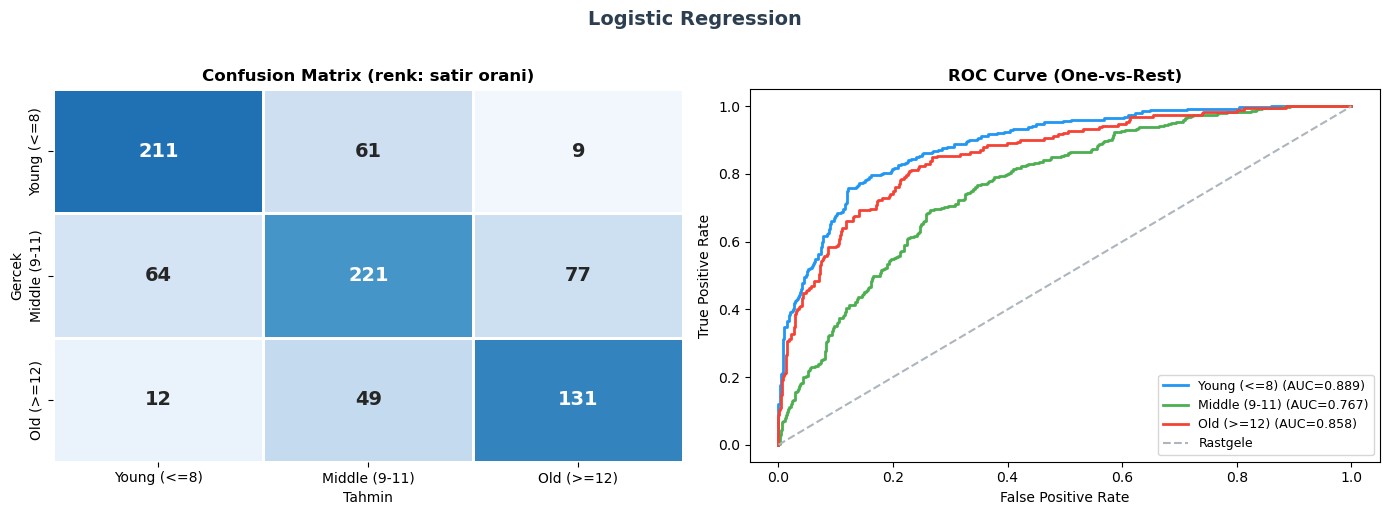


  KNN
               precision    recall  f1-score   support

  Young (<=8)     0.7718    0.6619    0.7126       281
Middle (9-11)     0.5979    0.7928    0.6817       362
   Old (>=12)     0.7281    0.4323    0.5425       192

     accuracy                         0.6659       835
    macro avg     0.6993    0.6290    0.6456       835
 weighted avg     0.6864    0.6659    0.6601       835



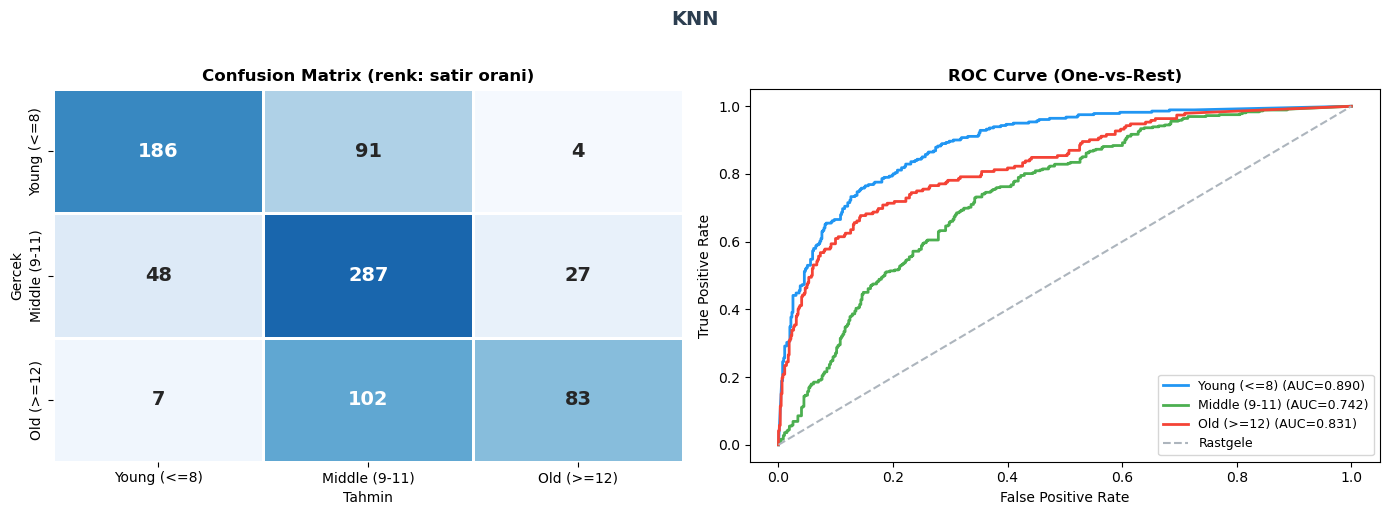


  Decision Tree
               precision    recall  f1-score   support

  Young (<=8)     0.6973    0.6477    0.6716       281
Middle (9-11)     0.5928    0.5912    0.5920       362
   Old (>=12)     0.5540    0.6146    0.5827       192

     accuracy                         0.6156       835
    macro avg     0.6147    0.6178    0.6154       835
 weighted avg     0.6190    0.6156    0.6166       835



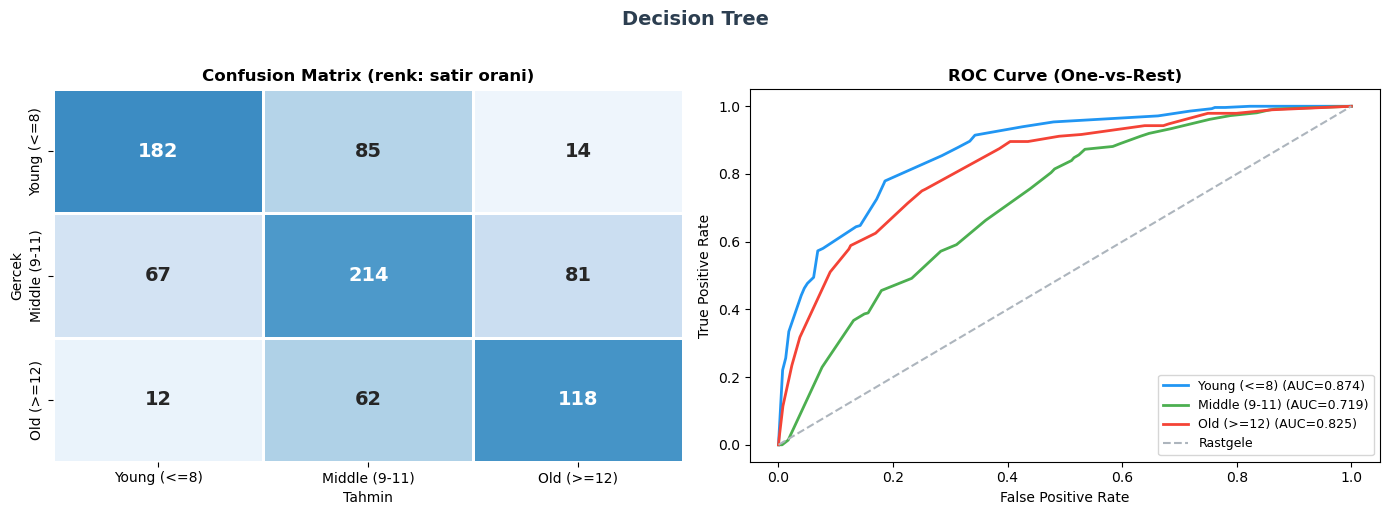


  Pruned Tree
               precision    recall  f1-score   support

  Young (<=8)     0.7215    0.6085    0.6602       281
Middle (9-11)     0.5907    0.5939    0.5923       362
   Old (>=12)     0.5427    0.6615    0.5962       192

     accuracy                         0.6144       835
    macro avg     0.6183    0.6213    0.6163       835
 weighted avg     0.6237    0.6144    0.6161       835



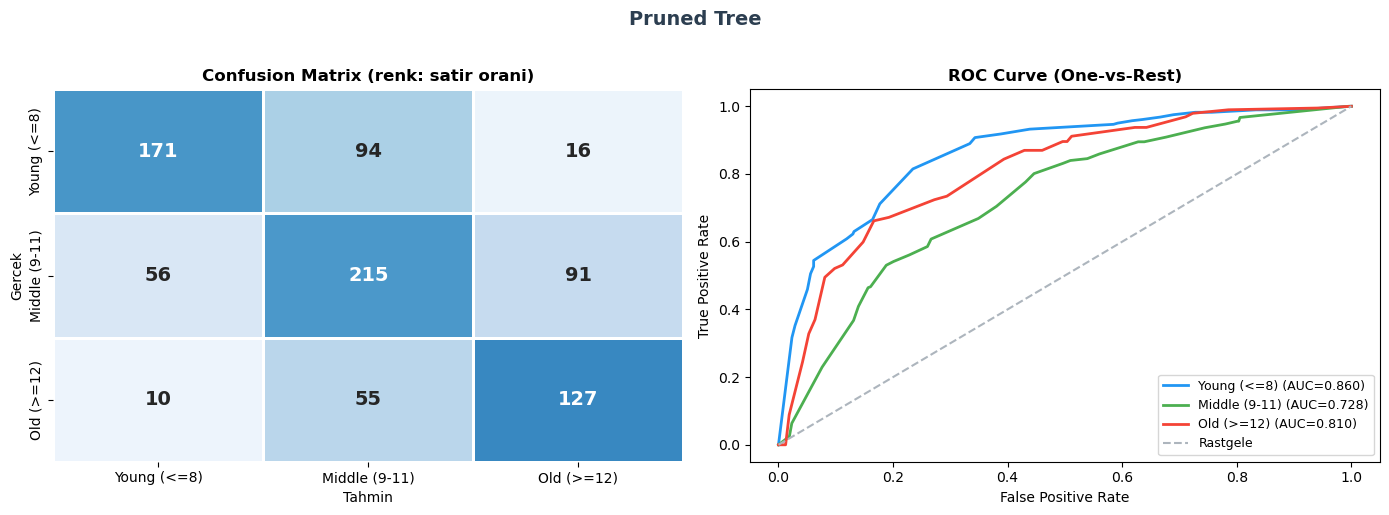


  Bagging
               precision    recall  f1-score   support

  Young (<=8)     0.7627    0.6406    0.6963       281
Middle (9-11)     0.6040    0.7541    0.6708       362
   Old (>=12)     0.6531    0.5000    0.5664       192

     accuracy                         0.6575       835
    macro avg     0.6733    0.6316    0.6445       835
 weighted avg     0.6687    0.6575    0.6554       835



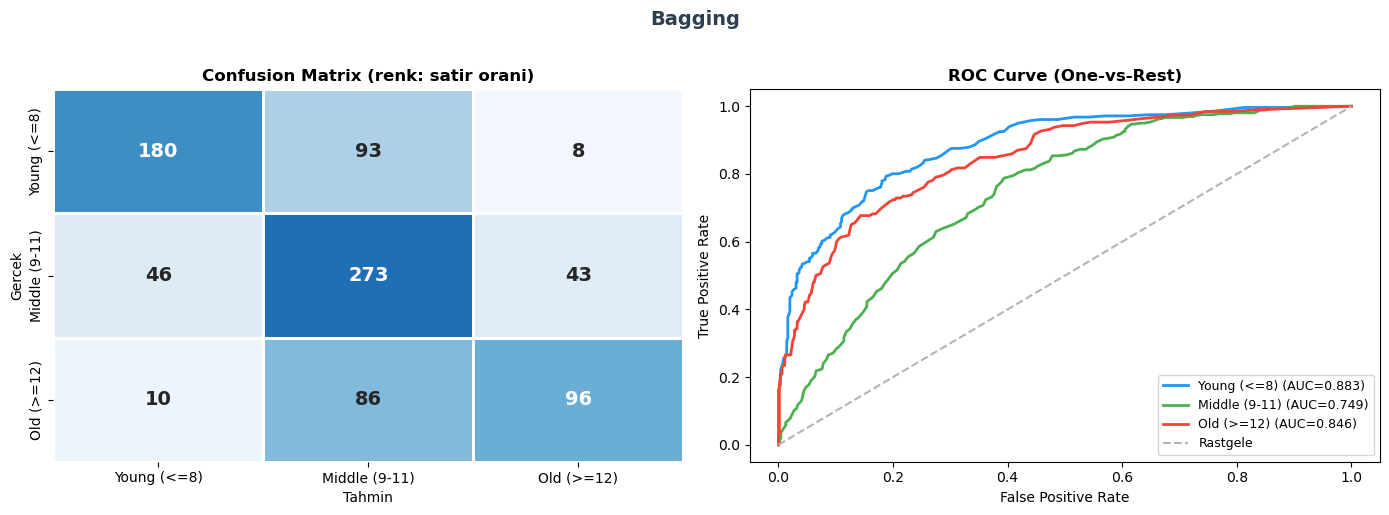


  Random Forest
               precision    recall  f1-score   support

  Young (<=8)     0.7470    0.6726    0.7079       281
Middle (9-11)     0.6332    0.6961    0.6632       362
   Old (>=12)     0.6630    0.6354    0.6489       192

     accuracy                         0.6743       835
    macro avg     0.6811    0.6680    0.6733       835
 weighted avg     0.6784    0.6743    0.6749       835



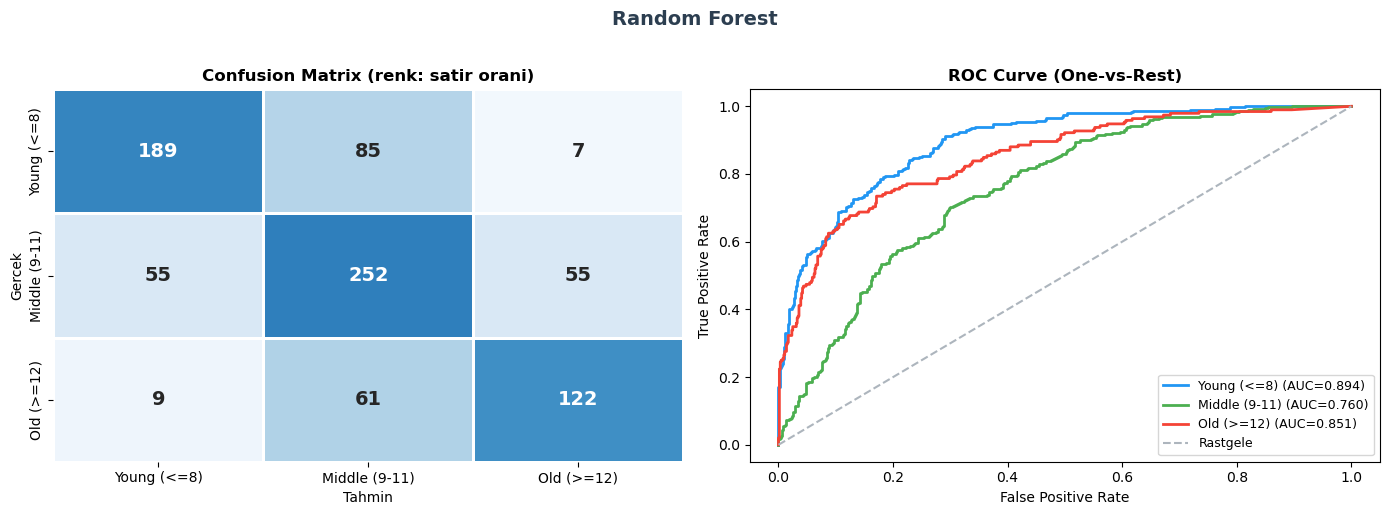


  XGBoost
               precision    recall  f1-score   support

  Young (<=8)     0.7378    0.7011    0.7190       281
Middle (9-11)     0.6648    0.6409    0.6526       362
   Old (>=12)     0.6210    0.7083    0.6618       192

     accuracy                         0.6766       835
    macro avg     0.6745    0.6834    0.6778       835
 weighted avg     0.6793    0.6766    0.6771       835



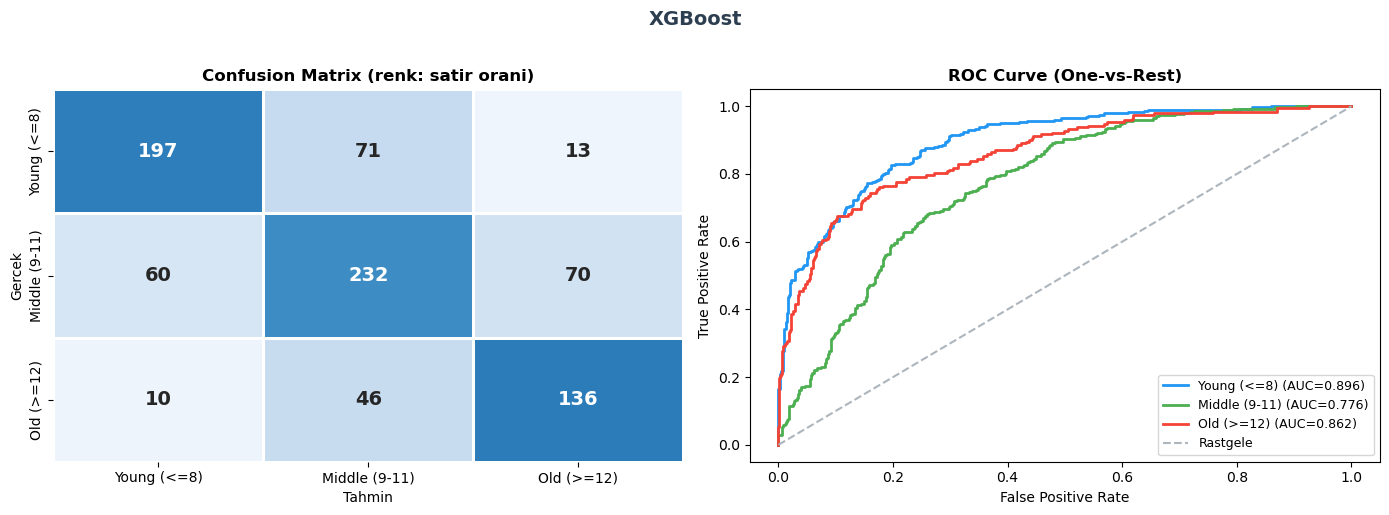

In [22]:
final_models, final_sonuclar, test_preds = {}, [], {}

for name in GRIDS:
    model = build(name, BEST_STRATEGY)
    model.fit(X_train, y_train, **(fit_params(name, BEST_STRATEGY) or {}))
    final_models[name] = model
    sonuc, test_preds[name] = model_degerlendir(name, model, X_test, y_test)
    final_sonuclar.append(sonuc)

### 7.1 Karşılaştırma — CV ve test, belirsizlikle birlikte

Test seti 835 gözlemdir; bu büyüklükte F1-macro'daki ±0.01'lik farklar rastlantısal olabilir.
Bu nedenle test F1 için **%95 bootstrap güven aralığı** (1000 yeniden örnekleme) ve eğitimdeki CV skoru birlikte verilir.

In [23]:
rng   = np.random.default_rng(RANDOM_STATE)
boots = rng.integers(0, len(y_test), size=(1000, len(y_test)))
yt    = y_test.to_numpy()

final_df = pd.DataFrame(final_sonuclar).set_index('Model')
cv_col   = strat_df.set_index(['Model', 'Strateji']).xs(BEST_STRATEGY, level='Strateji')
final_df.insert(0, 'CV F1 (egitim)', cv_col['CV F1'])
final_df.insert(1, 'CV std',         cv_col['CV std'])

ci = {}
for name, yp in test_preds.items():
    b = np.array([f1_score(yt[i], yp[i], average='macro') for i in boots])
    ci[name] = np.percentile(b, [2.5, 97.5])
final_df['F1 %95 GA'] = [f"[{ci[m][0]:.3f}, {ci[m][1]:.3f}]" for m in final_df.index]

final_df = final_df.sort_values('CV F1 (egitim)', ascending=False)
num = final_df.select_dtypes('number').columns
final_df.style.format({c: '{:.4f}' for c in num}) \
    .highlight_max(subset=[c for c in num if c != 'CV std'], color='#d4edda') \
    .set_caption('Tum modeller — CV (egitim) ve test performansi')

,CV F1 (egitim),CV std,Accuracy,Precision,Recall,Specificity,F1-macro,ROC-AUC,F1 %95 GA
Model,,,,,,,,,
Bagging,0.6759,0.0232,0.6575,0.6733,0.6316,0.8137,0.6445,0.8260,"[0.613, 0.676]"
Logistic Regression,0.6755,0.0204,0.6743,0.6689,0.6812,0.8322,0.6738,0.8379,"[0.641, 0.703]"
XGBoost,0.6754,0.0152,0.6766,0.6745,0.6834,0.8324,0.6778,0.8444,"[0.645, 0.708]"
Random Forest,0.6745,0.0200,0.6743,0.6811,0.6680,0.8265,0.6733,0.8350,"[0.642, 0.703]"
KNN,0.6500,0.0184,0.6659,0.6993,0.6290,0.8148,0.6456,0.8210,"[0.610, 0.676]"
Pruned Tree,0.6477,0.0133,0.6144,0.6183,0.6213,0.7998,0.6163,0.7995,"[0.584, 0.649]"
Decision Tree,0.6371,0.0205,0.6156,0.6147,0.6178,0.7996,0.6154,0.8061,"[0.583, 0.647]"


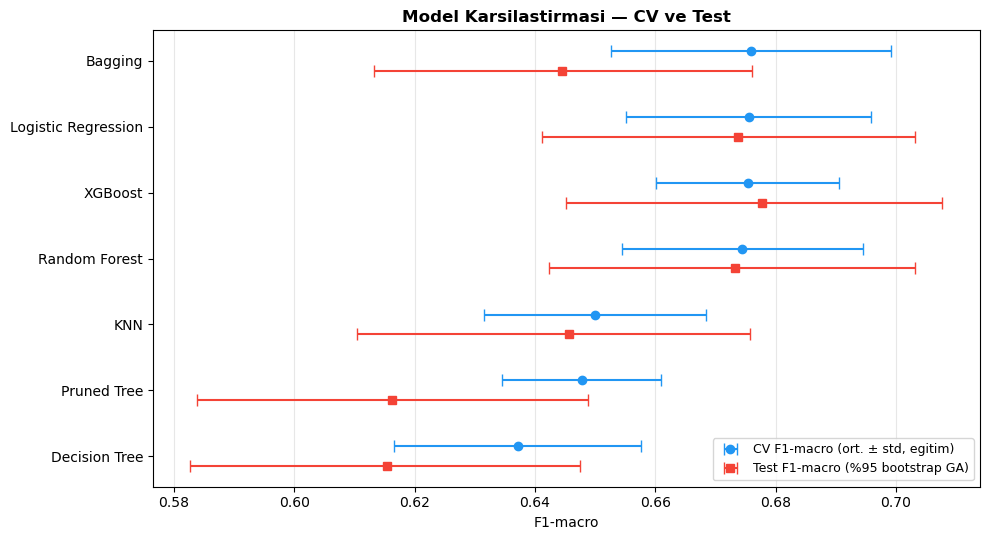

In [24]:
order = final_df.index[::-1]
with plt.style.context('default'):
    fig, ax = plt.subplots(figsize=(10, 5.5))
    yy = np.arange(len(order))
    ax.errorbar(final_df.loc[order, 'CV F1 (egitim)'], yy + 0.15,
                xerr=final_df.loc[order, 'CV std'], fmt='o', color='#2196F3',
                capsize=4, label='CV F1-macro (ort. ± std, egitim)')
    test_f1 = final_df.loc[order, 'F1-macro']
    lo = np.array([ci[m][0] for m in order]); hi = np.array([ci[m][1] for m in order])
    ax.errorbar(test_f1, yy - 0.15, xerr=[test_f1 - lo, hi - test_f1], fmt='s',
                color='#F44336', capsize=4, label='Test F1-macro (%95 bootstrap GA)')
    ax.set_yticks(yy); ax.set_yticklabels(order)
    ax.set_xlabel('F1-macro')
    ax.set_title('Model Karsilastirmasi — CV ve Test', fontweight='bold')
    ax.grid(axis='x', alpha=0.3)
    ax.legend(loc='lower right', fontsize=9)
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/model_karsilastirma.png', dpi=130, bbox_inches='tight', facecolor='white')
    plt.show()

**Yorum — model karşılaştırması**

- **Dengesizlik:** `class_weight` ortalama CV F1-macro'da en yüksek strateji (0.662), fakat `Yok` (0.660) ile fark çok küçüktür.
  SMOTE(NC) hiçbir modelde belirgin kazanç sağlamamış, çoğunda hafifçe düşürmüştür (ort. 0.654).
- **Dört model istatistiksel olarak başabaştır:** Bagging, Lojistik Regresyon, XGBoost ve Random Forest'ın CV F1-macro
  değerleri 0.674–0.676 aralığındadır (std ≈ 0.02) ve test F1 güven aralıkları büyük ölçüde örtüşür.
  Dolayısıyla "XGBoost açık ara en iyi model" demek veriyle desteklenmez; doğru ifade
  *"topluluk yöntemleri ve lojistik regresyon benzer performans gösterir"* şeklindedir.
- Tek karar ağaçları (budanmış/budanmamış) ve KNN belirgin şekilde geride kalmıştır (test F1 ≈ 0.62–0.65).
- Basit **lojistik regresyonun** topluluk modelleriyle aynı düzeyde olması, sınıf sınırlarının büyük ölçüde
  (ağırlık ölçümlerinde) monoton/doğrusala yakın olduğuna işaret eder.
- Hata yapısı: en zor sınıf **Middle**'dır; iki komşu sınıfla karışır. Young ↔ Old karışıklığı ise nadirdir —
  hedef sıralı (ordinal) olduğu için beklenen bir durumdur.
- F1 ≈ 0.68 tavanı veri setinin doğasından kaynaklanır: aynı boyutta iki abalone çok farklı yaşta olabilir
  (büyüme yaşla birlikte yavaşlar); bu nedenle sınıf sınırları (8/9 ve 11/12 halka) civarında hata kaçınılmazdır.

## 8. Açıklanabilirlik — SHAP (XGBoost)

SHAP analizi XGBoost modeli üzerinde yapılır: ağaç modelleri için `TreeExplainer` kesin (exact)
Shapley değerleri hesaplar ve XGBoost'un performansı en iyi modellerle istatistiksel olarak aynı düzeydedir.

> **Önemli:** XGBoost'ta çok sınıflı SHAP değerleri **olasılık değil, ham skor (logit / log-odds)**
> ölçeğindedir. Pozitif değer o sınıfın skorunu artırır, negatif değer azaltır.

In [25]:
xgb_model = final_models['XGBoost']
if hasattr(xgb_model, 'named_steps'):          # SMOTE secildiyse pipeline icindedir
    xgb_model = xgb_model.named_steps['model']

explainer   = shap.TreeExplainer(xgb_model)
shap_exp    = explainer(X_test)                # Explanation: (n, ozellik, sinif)
shap_values = shap_exp.values
feat_names  = FEATURES

print(f"SHAP deger matrisi sekli: {shap_values.shape}")

SHAP deger matrisi sekli: (835, 9, 3)


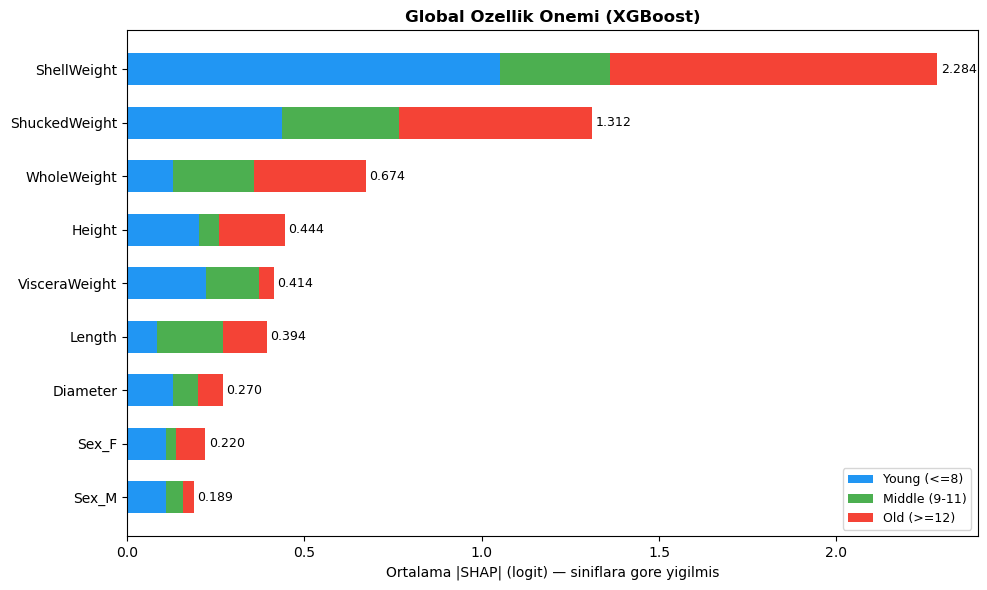

In [26]:
mean_abs = pd.DataFrame(np.abs(shap_values).mean(axis=0), index=feat_names, columns=CLASS_NAMES)
mean_abs['Toplam'] = mean_abs.sum(axis=1)
mean_abs = mean_abs.sort_values('Toplam')

with plt.style.context('default'):
    fig, ax = plt.subplots(figsize=(10, 6))
    left = np.zeros(len(mean_abs))
    for sinif, renk in zip(CLASS_NAMES, SINIF_RENK):
        ax.barh(mean_abs.index, mean_abs[sinif], left=left, color=renk, label=sinif, height=0.6)
        left += mean_abs[sinif].values
    for yi, v in enumerate(mean_abs['Toplam']):
        ax.text(v + 0.01, yi, f'{v:.3f}', va='center', fontsize=9)
    ax.set_xlabel('Ortalama |SHAP| (logit) — siniflara gore yigilmis')
    ax.set_title('Global Ozellik Onemi (XGBoost)', fontweight='bold')
    ax.legend(fontsize=9, loc='lower right')
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/shap_importance.png', dpi=130, bbox_inches='tight', facecolor='white')
    plt.show()

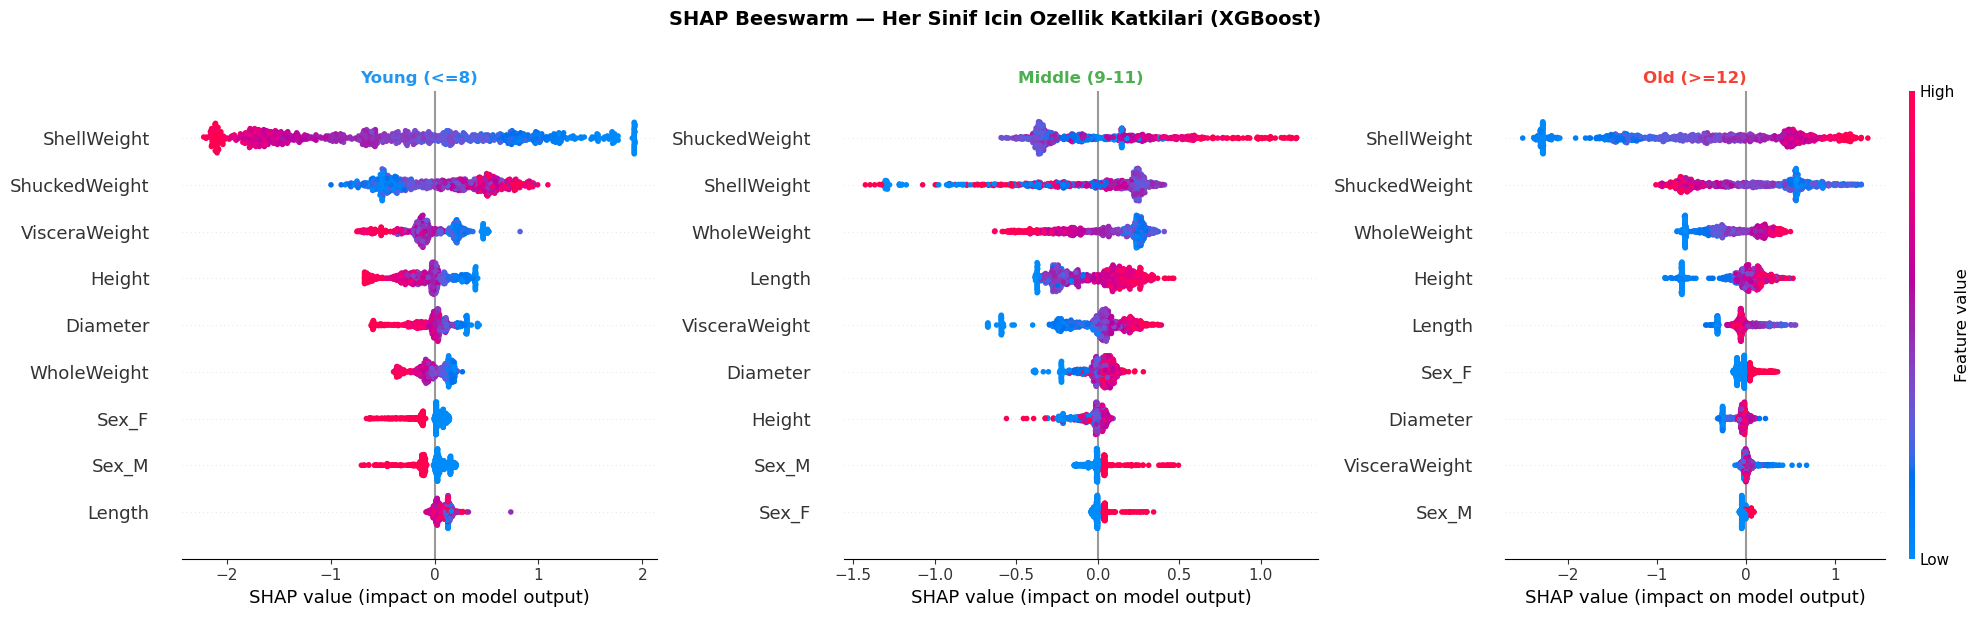

In [27]:
with plt.style.context('default'):
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))
    for k, sinif in enumerate(CLASS_NAMES):
        plt.sca(axes[k])
        shap.summary_plot(shap_values[:, :, k], X_test, feature_names=feat_names,
                          plot_type='dot', max_display=9, show=False,
                          plot_size=None, color_bar=(k == 2))
        axes[k].set_title(sinif, fontsize=12, fontweight='bold', color=SINIF_RENK[k])
    fig.suptitle('SHAP Beeswarm — Her Sinif Icin Ozellik Katkilari (XGBoost)',
                 fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/shap_beeswarm.png', dpi=130, bbox_inches='tight', facecolor='white')
    plt.show()

### 8.1 Yön tablosu

Grafik yorumlarını sayıya dayandırmak için her özelliğin **değeri** ile **SHAP katkısı** arasındaki
Spearman korelasyonu hesaplanır: pozitif ρ → değer arttıkça o sınıfın skoru artar.

In [28]:
yon = pd.DataFrame({sinif: [stats.spearmanr(X_test[f], shap_values[:, j, k])[0]
                            for j, f in enumerate(feat_names)]
                    for k, sinif in enumerate(CLASS_NAMES)}, index=feat_names)
yon = yon.loc[mean_abs.index[::-1]]
yon.style.format('{:+.2f}').background_gradient(cmap='RdBu_r', vmin=-1, vmax=1) \
   .set_caption('Spearman rho (ozellik degeri, SHAP degeri) — onem sirasina gore')

,Young (<=8),Middle (9-11),Old (>=12)
ShellWeight,-0.98,+0.03,+0.98
ShuckedWeight,+0.88,+0.47,-0.88
WholeWeight,-0.93,-0.84,+0.97
Height,-0.92,+0.32,+0.75
VisceraWeight,-0.83,+0.92,-0.01
Length,-0.33,+0.90,-0.13
Diameter,-0.88,+0.53,+0.44
Sex_F,-0.81,+0.81,+0.81
Sex_M,-0.84,+0.84,+0.82


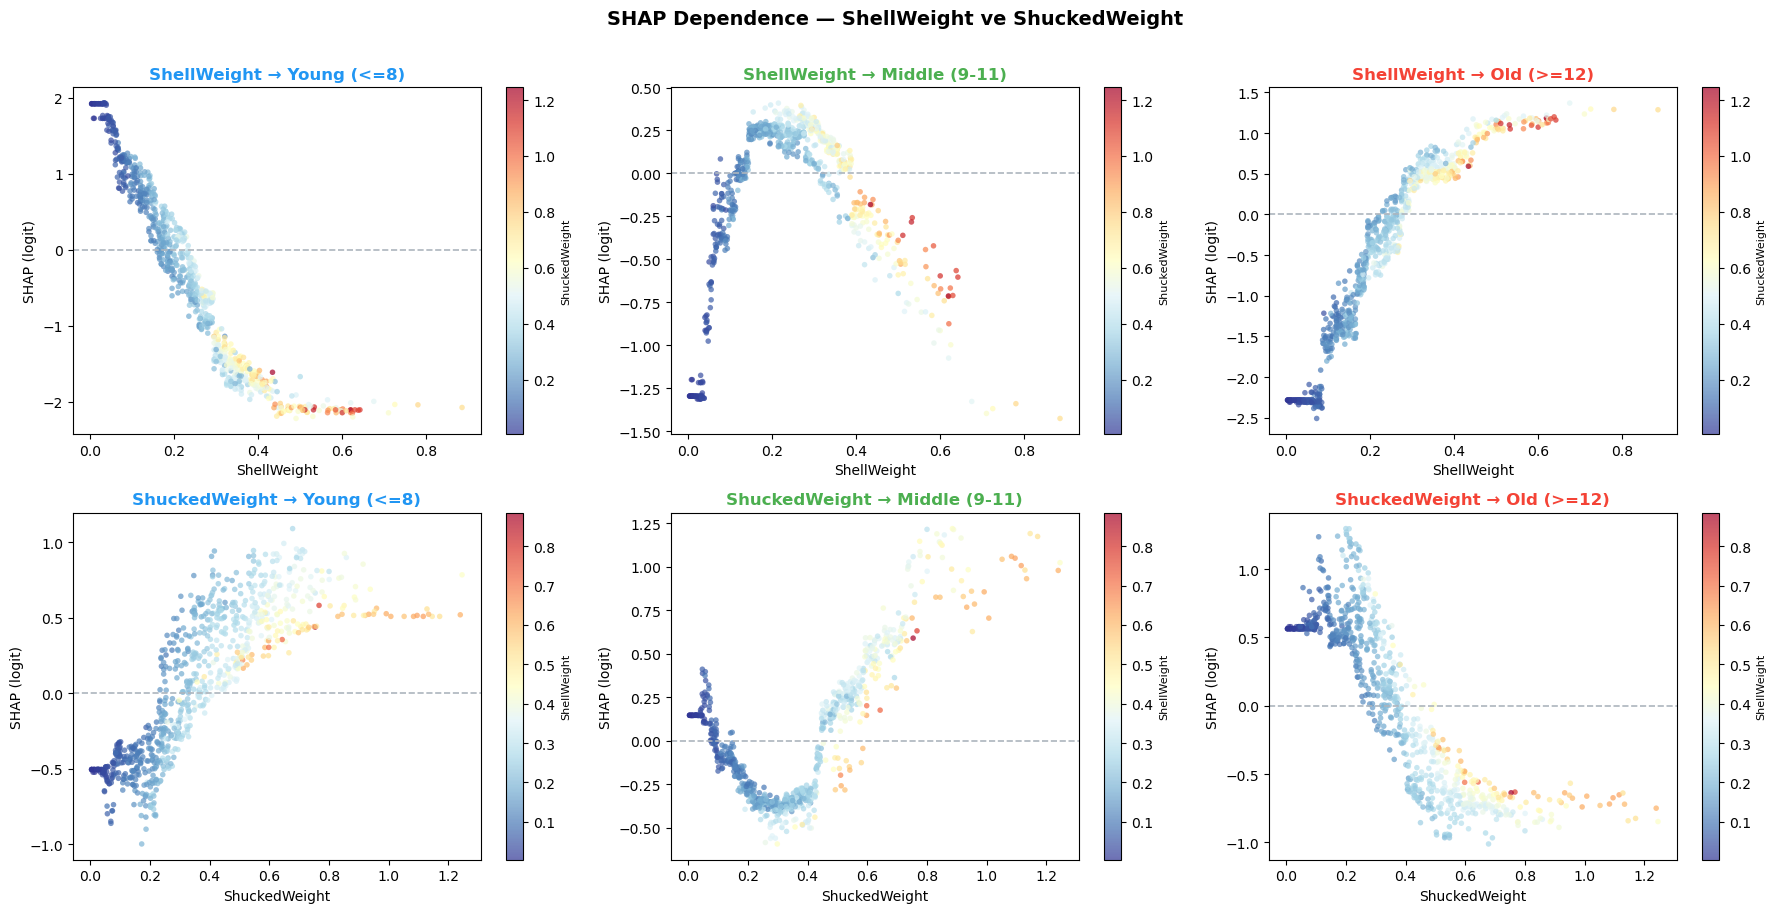

In [29]:
shell_idx, shuck_idx = feat_names.index('ShellWeight'), feat_names.index('ShuckedWeight')

with plt.style.context('default'):
    fig, axes = plt.subplots(2, 3, figsize=(18, 9))
    for row, (fi, ci_) in enumerate([(shell_idx, shuck_idx), (shuck_idx, shell_idx)]):
        for k, sinif in enumerate(CLASS_NAMES):
            ax = axes[row, k]
            sc = ax.scatter(X_test.iloc[:, fi], shap_values[:, fi, k],
                            c=X_test.iloc[:, ci_], cmap='RdYlBu_r', s=16, alpha=0.7, edgecolors='none')
            ax.axhline(0, color='#adb5bd', lw=1.2, ls='--')
            ax.set_xlabel(feat_names[fi]); ax.set_ylabel('SHAP (logit)')
            ax.set_title(f'{feat_names[fi]} → {sinif}', fontweight='bold', color=SINIF_RENK[k])
            plt.colorbar(sc, ax=ax).set_label(feat_names[ci_], fontsize=8)
    fig.suptitle('SHAP Dependence — ShellWeight ve ShuckedWeight', fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/shap_dependence.png', dpi=130, bbox_inches='tight', facecolor='white')
    plt.show()

**Yorum — SHAP bulguları** (yön tablosu ve dependence grafiklerine dayanarak)

- **ShellWeight** açık ara en önemli değişkendir. Değeri arttıkça **Old** skoru artar (ρ = +0.98),
  **Young** skoru düşer (ρ = −0.98); Middle için yön belirsizdir (ρ ≈ 0), çünkü Middle orta değerlerde desteklenir.
- **ShuckedWeight** ikinci sıradadır ve **ShellWeight'in tersine** çalışır: diğer ölçümler sabitken et ağırlığı
  yüksek olan birey *daha genç* tahmin edilir (Young ρ = +0.88, Old ρ = −0.88). Biyolojik olarak yaşlı abalonelerde
  kabuk kalınlaşır, toplam ağırlık içinde etin payı azalır.
  > *İlk sürümdeki "ShuckedWeight de aynı yönde hareket ediyor, iki değişken birlikte çalışıyor" yorumu
  > verilerle çelişmektedir — iki değişken birbiriyle yüksek korelasyonlu olsa da model içindeki katkıları zıt yönlüdür.*
- **Sex_F / Sex_M** (referans: yavru) Young skorunu düşürür: yetişkin olarak sınıflanmış bir bireyin genç olma ihtimali düşüktür.
- Ölçümler arasında çok yüksek korelasyon olduğundan, tek tek SHAP değerleri nedensel etki olarak değil,
  *modelin bu korelasyonlu değişkenler arasında katkıyı nasıl paylaştırdığı* olarak okunmalıdır.

### 8.2 Bireysel tahminler — Waterfall ve Decision Plot

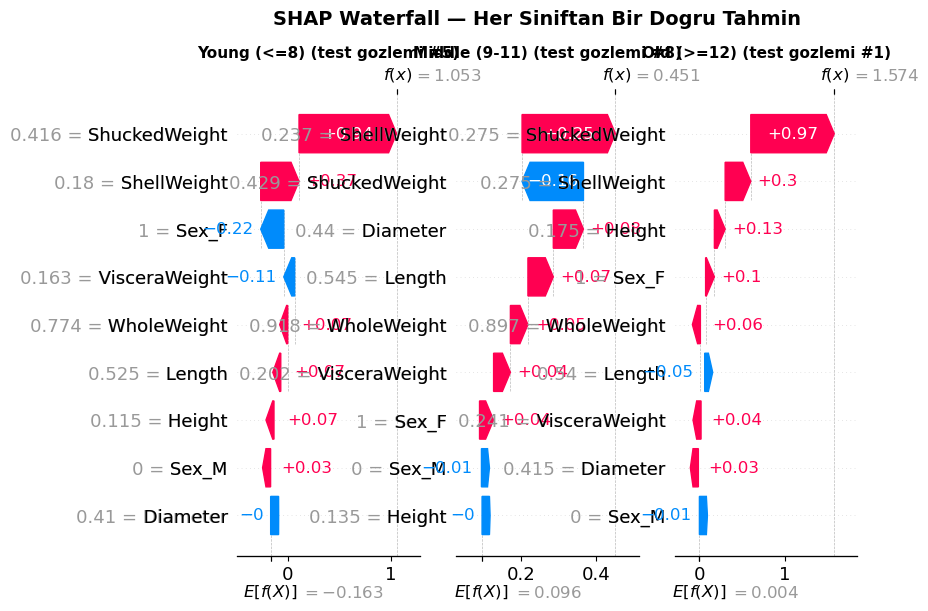

In [30]:
y_pred_xgb = xgb_model.predict(X_test)

with plt.style.context('default'):
    fig, axes = plt.subplots(1, 3, figsize=(21, 6))
    for k, sinif in enumerate(CLASS_NAMES):
        dogru = np.where((y_test.values == k) & (y_pred_xgb == k))[0]
        idx   = dogru[0]
        plt.sca(axes[k])
        shap.plots.waterfall(shap_exp[idx, :, k], max_display=9, show=False)
        axes[k].set_title(f'{sinif} (test gozlemi #{idx})', fontsize=11, fontweight='bold')
    fig.suptitle('SHAP Waterfall — Her Siniftan Bir Dogru Tahmin', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/shap_waterfall.png', dpi=130, bbox_inches='tight', facecolor='white')
    plt.show()

**Decision plot düzeltmesi:** İlk sürümde her gözlemin kümülatif çizgisi *kendi* özellik sırasına göre
çiziliyor, y-ekseni etiketleri ise *ortalama* sıraya göre yazılıyordu; çizgiler etiketlerle eşleşmiyordu.
Artık tüm çizgiler aynı (ortalama |SHAP|) sırayı kullanır.

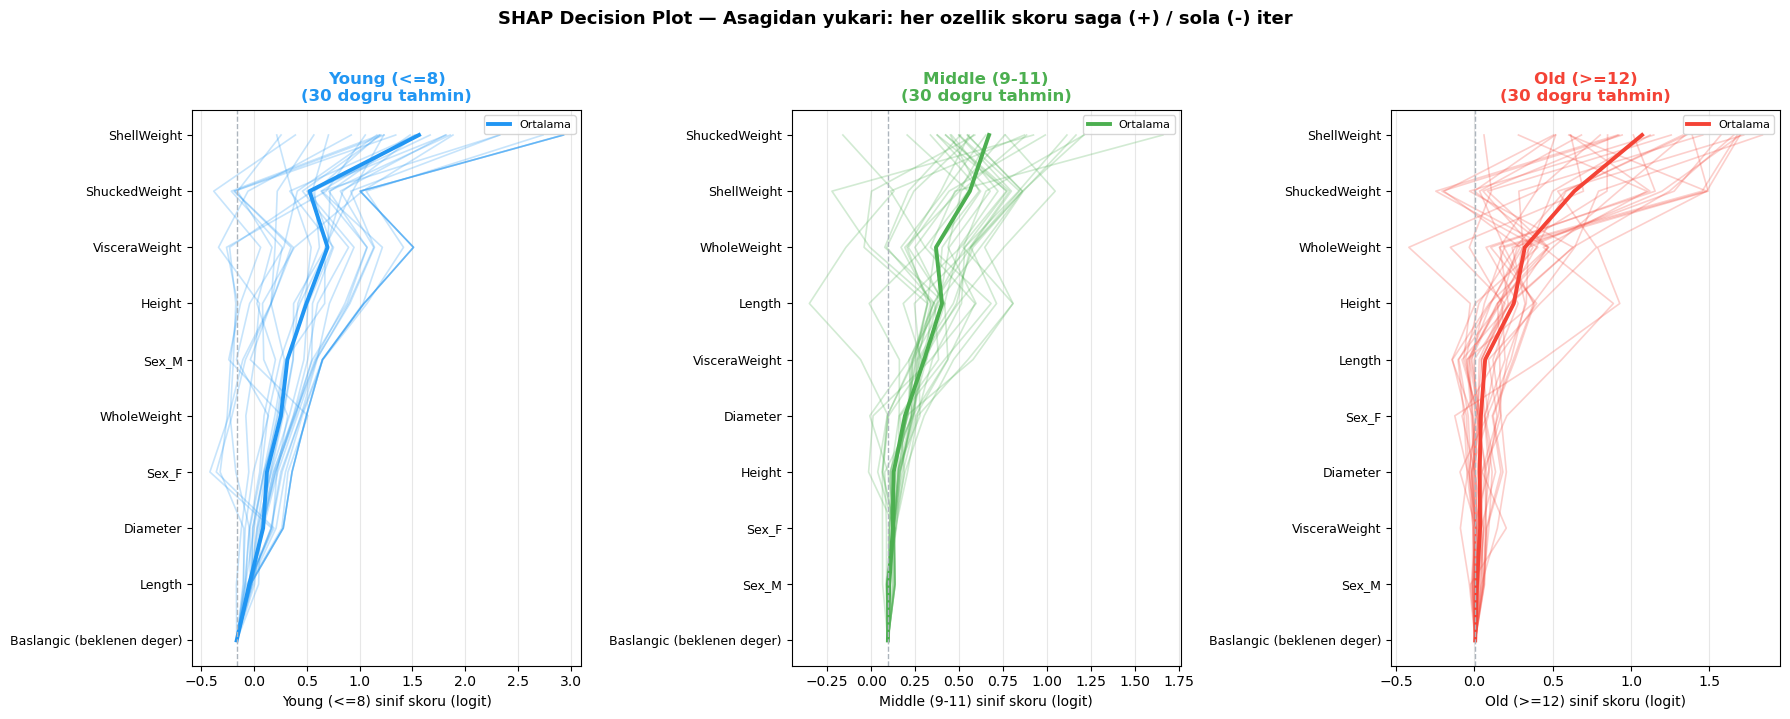

In [31]:
with plt.style.context('default'):
    fig, axes = plt.subplots(1, 3, figsize=(18, 7))
    for k, (sinif, renk) in enumerate(zip(CLASS_NAMES, SINIF_RENK)):
        ax       = axes[k]
        secilen  = np.where((y_test.values == k) & (y_pred_xgb == k))[0][:30]
        sv_k     = shap_values[secilen, :, k]
        base_val = explainer.expected_value[k]
        sira     = np.argsort(np.abs(sv_k).mean(axis=0))      # tum cizgiler icin ortak sira
        y_pos    = np.arange(len(feat_names) + 1)

        for i in range(len(secilen)):
            ax.plot(base_val + np.concatenate([[0], np.cumsum(sv_k[i, sira])]),
                    y_pos, color=renk, alpha=0.25, lw=1.2)
        ax.plot(base_val + np.concatenate([[0], np.cumsum(sv_k.mean(axis=0)[sira])]),
                y_pos, color=renk, lw=2.8, label='Ortalama')

        ax.axvline(base_val, color='#adb5bd', lw=1, ls='--')
        ax.set_yticks(y_pos)
        ax.set_yticklabels(['Baslangic (beklenen deger)'] + [feat_names[j] for j in sira], fontsize=9)
        ax.set_xlabel(f'{sinif} sinif skoru (logit)')
        ax.set_title(f'{sinif}\n({len(secilen)} dogru tahmin)', fontweight='bold', color=renk)
        ax.legend(fontsize=8)
        ax.grid(axis='x', alpha=0.3)
    fig.suptitle('SHAP Decision Plot — Asagidan yukari: her ozellik skoru saga (+) / sola (-) iter',
                 fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/shap_decision.png', dpi=130, bbox_inches='tight', facecolor='white')
    plt.show()

**Yorum — decision plot**

- Her çizgi bir test gözlemidir; alttaki beklenen değerden başlar, her özellik skoru sağa (+) veya sola (−) iter.
- **Young** için doğru tahminlerde **ShellWeight skoru güçlü biçimde sağa iter** (düşük kabuk ağırlığı Young'ı destekler);
  ShuckedWeight ortalamada hafifçe sola iter.
  > *İlk sürümdeki "Young sınıfında ShellWeight ve ShuckedWeight güçlü bir şekilde sola itiyor (Old/Middle ihtimalini
  > düşürüyor)" yorumu yanlıştı: doğru tahmin edilmiş Young gözlemlerinde ShellWeight sağa iter; ayrıca bir sınıfın
  > grafiğinde sola itmek **o sınıfın** skorunu düşürmek demektir, diğer sınıflarınkini değil.*
- **Old** için ShellWeight ve ShuckedWeight en büyük katkıyı yapar; **Middle**'da katkılar daha dağınıktır ve
  çizgilerin yayılımı büyüktür — Middle'ın en zor sınıf olmasıyla tutarlıdır.

## 9. Etkileşimli Tahmin Aracı (XGBoost + SHAP + LLM)

Kullanıcı ölçümleri **gerçek birimlerle (mm, g)** girer; değerler modele verilmeden önce veri
setindeki ölçeğe çevrilir (÷200). Tahmin, en etkili SHAP katkıları ve Groq üzerinden Llama 3.1'in
kısa bir yorumu gösterilir.

> **Güvenlik:** API anahtarı koda yazılmaz. Çalıştırmadan önce ortam değişkeni olarak tanımlayın:
> `set GROQ_API_KEY=...` (Windows) / `export GROQ_API_KEY=...` (Linux/macOS).
> Anahtar yoksa araç LLM yorumu olmadan çalışır. *(Widget'lar GitHub önizlemesinde görünmez; notebook'u Jupyter'de açın.)*

In [32]:
import joblib
os.makedirs('models', exist_ok=True)
joblib.dump({'model': xgb_model, 'features': FEATURES, 'classes': CLASS_NAMES},
            'models/xgb_model.pkl')
print("Model kaydedildi: models/xgb_model.pkl")

Model kaydedildi: models/xgb_model.pkl


In [33]:
import ipywidgets as widgets
from IPython.display import clear_output

try:
    from groq import Groq
    client = Groq() if os.environ.get('GROQ_API_KEY') else None
except ImportError:
    client = None
print("LLM yorumu:", "aktif" if client else "kapali (GROQ_API_KEY yok veya groq kurulu degil)")

OLCEK  = 200                                   # UCI verisi orijinal birimlerin 1/200'u
style  = {'description_width': '170px'}
layout = widgets.Layout(width='420px')

def sayi_kutusu(col, etiket):
    lo, hi, med = (X_train[col].min() * OLCEK, X_train[col].max() * OLCEK,
                   X_train[col].median() * OLCEK)
    return widgets.BoundedFloatText(value=round(med, 1), min=round(lo, 1), max=round(hi, 1),
                                    step=0.5, description=etiket, style=style, layout=layout)

girdiler = {
    'Length'       : sayi_kutusu('Length',        'Uzunluk (mm):'),
    'Diameter'     : sayi_kutusu('Diameter',      'Cap (mm):'),
    'Height'       : sayi_kutusu('Height',        'Yukseklik (mm):'),
    'WholeWeight'  : sayi_kutusu('WholeWeight',   'Toplam agirlik (g):'),
    'ShuckedWeight': sayi_kutusu('ShuckedWeight', 'Et agirligi (g):'),
    'VisceraWeight': sayi_kutusu('VisceraWeight', 'Ic organ agirligi (g):'),
    'ShellWeight'  : sayi_kutusu('ShellWeight',   'Kabuk agirligi (g):'),
}
w_sex  = widgets.RadioButtons(options=[('Erkek (M)', 'M'), ('Disi (F)', 'F'), ('Yavru (I)', 'I')],
                              value='M', description='Cinsiyet:', style=style)
btn    = widgets.Button(description='Tahmin Et', button_style='primary',
                        layout=widgets.Layout(width='420px', height='40px'))
output = widgets.Output()

RENK = dict(zip(CLASS_NAMES, ['#10b981', '#f59e0b', '#ef4444']))

def tahmin_et(_):
    with output:
        clear_output(wait=True)
        satir = {c: w.value / OLCEK for c, w in girdiler.items()}
        satir.update({'Sex_F': float(w_sex.value == 'F'), 'Sex_M': float(w_sex.value == 'M')})
        X_in = pd.DataFrame([satir])[FEATURES]

        probs    = xgb_model.predict_proba(X_in)[0]
        pred_idx = int(np.argmax(probs))
        pred_cls = CLASS_NAMES[pred_idx]

        sv = explainer(X_in).values[0, :, pred_idx]
        shap_df = pd.DataFrame({'Ozellik': FEATURES, 'SHAP': sv}) \
                    .sort_values('SHAP', key=abs, ascending=False).head(5)

        yorum = "LLM yorumu kapali (GROQ_API_KEY tanimli degil)."
        if client is not None:
            top3 = ", ".join(f"{r.Ozellik}={r.SHAP:+.3f}" for r in shap_df.head(3).itertuples())
            olcumler = ", ".join(f"{w.description.rstrip(':')} {w.value}" for w in girdiler.values())
            try:
                msg = client.chat.completions.create(
                    model="llama-3.1-8b-instant", max_tokens=200,
                    messages=[{"role": "user", "content":
                        f"Sen bir deniz biyologusun. Abalone olcumleri: {olcumler}, "
                        f"cinsiyet: {w_sex.value}.\nModel tahmini: {pred_cls} "
                        f"(%{probs[pred_idx]*100:.1f}). En etkili SHAP katkilari (logit, "
                        f"pozitif = bu sinifi destekler): {top3}.\n"
                        "2-3 cumle, sade Turkce: neden bu yas grubu, hangi olcum etkili, biyolojik yorum."}])
                yorum = msg.choices[0].message.content
            except Exception as e:
                yorum = f"LLM cagrisi basarisiz: {e}"

        prob_html = "".join(
            f"<div style='display:flex;gap:10px;align-items:center;margin-bottom:6px'>"
            f"<div style='width:130px;color:#94a3b8'>{c}</div>"
            f"<div style='width:{int(p*200)}px;height:8px;background:{RENK[c]};border-radius:4px'></div>"
            f"<div style='color:#e2e8f0'>%{p*100:.1f}</div></div>"
            for c, p in zip(CLASS_NAMES, probs))
        shap_html = "".join(
            f"<div style='color:{'#ef4444' if r.SHAP > 0 else '#2196F3'}'>"
            f"{'▲' if r.SHAP > 0 else '▼'} {r.Ozellik}: {r.SHAP:+.4f}</div>"
            for r in shap_df.itertuples())

        display(widgets.HTML(f'''
        <div style="background:#0f1724;border-radius:12px;padding:20px;font-family:monospace;color:#e2e8f0">
          <div style="border-left:4px solid {RENK[pred_cls]};padding-left:14px;margin-bottom:16px">
            <div style="color:#64748b;font-size:0.75rem">TAHMIN</div>
            <div style="color:{RENK[pred_cls]};font-size:1.4rem;font-weight:bold">{pred_cls}</div></div>
          <div style="margin-bottom:16px">{prob_html}</div>
          <div style="margin-bottom:16px"><div style="color:#64748b;font-size:0.75rem">EN ETKILI OZELLIKLER (SHAP, logit)</div>{shap_html}</div>
          <div style="border-top:1px solid #1e2d40;padding-top:12px;line-height:1.6">{yorum}</div>
        </div>'''))

btn.on_click(tahmin_et)
display(widgets.HTML("<h3>Abalone Yas Grubu Tahmin Sistemi</h3>"),
        widgets.HBox([widgets.VBox(list(girdiler.values())), w_sex]), btn, output)

LLM yorumu: kapali (GROQ_API_KEY yok veya groq kurulu degil)


HTML(value='<h3>Abalone Yas Grubu Tahmin Sistemi</h3>')

Button(button_style='primary', description='Tahmin Et', layout=Layout(height='40px', width='420px'), style=But…

Output()

## 10. Sonuç

1. Fiziksel ölçümlerle abalone yaş grubu **F1-macro ≈ 0.67–0.68, ROC-AUC ≈ 0.84** düzeyinde tahmin edilebilmektedir.
2. Topluluk yöntemleri (XGBoost, Random Forest, Bagging) ve lojistik regresyon istatistiksel olarak benzer performans
   gösterir; tek karar ağaçları ve KNN daha zayıftır.
3. Sınıf dengesizliği orta düzeydedir; `class_weight` küçük bir iyileşme sağlamış, SMOTE katkı sağlamamıştır.
4. SHAP analizine göre yaşın en güçlü göstergesi **kabuk ağırlığıdır**; et ağırlığı ise (diğer ölçümler sabitken) ters yönde,
   gençliğe işaret eder.
5. Sınırlılıklar: hedef sıralı olduğu hâlde nominal sınıflandırma yapılmıştır (ordinal yöntemler veya `Rings` üzerinde
   regresyon + eşikleme denenebilir); sınıf sınırları (8 / 11 halka) keyfidir ve sınır civarındaki hatalar kaçınılmazdır.